# Ok-k-mer

Use python310 conda environment

## Imports

In [1]:
import ok_k_mer

In [2]:
import os
from random import randint
import multiprocessing as mp
from random import sample
from random import sample, seed as set_seed, randint
import numpy as np
import pandas as pd
from collections import Counter
from ete3 import Tree
from itertools import combinations, product
from scipy.stats import binom, geom, spearmanr, pearsonr

pd.options.display.max_rows = 40



In [3]:
# import matplotlib
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mplpatches
import matplotlib.colors as mcolors
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
%matplotlib inline

plt.rcParams['figure.dpi'] = 300
plt.rcParams['agg.path.chunksize'] = 10000

In [4]:
import warnings
warnings.filterwarnings("ignore")


In [5]:
# import plotnine

from plotnine import \
    ggplot, aes, theme, themes, element_blank, element_line, element_text, mapping, \
    geom_point, geom_jitter, geom_line, geom_bar, geom_boxplot, geom_violin, geom_histogram, \
    ggtitle, xlab, ylab, geom_vline, geom_hline, geom_abline, geom_col, geom_tile, \
    scale_x_discrete, scale_y_discrete, scale_x_continuous, scale_y_continuous, \
    scale_color_discrete, scale_fill_manual, scale_fill_hue, scale_fill_gradient, scale_color_manual, scale_color_hue, \
    guides, after_stat, \
    xlim, ylim
from plotnine.options import figure_size
from mizani.formatters import percent_format

# plotnine theme
def theme_tufte_func(base_size=19, base_family="sans", rotate=True, figure_size=None):
    ''' Plotnine plotting theme. '''
    thm = themes.theme_bw(base_size=base_size, base_family = base_family) + \
        theme(
            legend_background = element_blank(),
            legend_key = element_blank(),
            panel_background = element_blank(),
            panel_border = element_blank(),
            strip_background = element_blank(),
            plot_background = element_blank(),
            panel_grid = element_blank(),
            axis_line = element_line(colour = "black", size = 1),
            axis_text_y = element_text(colour = "black")
        )

    if rotate:
        thm += theme(axis_text_x=element_text(rotation=45, hjust=1))
    if figure_size is not None:
        thm += theme(figure_size=figure_size)
    return thm


## Process/Load data

In [6]:
# Load merged_dfs
#
#aquificota_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/dashingfull_genomes_ncbi'
#bacillales_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/dashingfull_genomes_ncbi'
#caldisericia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/dashingfull_genomes_ncbi'
#chlamydia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/dashingfull_genomes_ncbi'
#cyano_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/dashingfull_genomes_ncbi'
#neisseriaceae_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/dashingfull_genomes_ncbi'
#
#aquificota_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/p__Aquificota.nwk'
#bacillales_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/o__Bacillales_A.nwk'
#caldisericia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/c__Caldisericia.nwk'
#chlamydia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/o__Chlamydiales.nwk'
#cyano_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/o__Cyanobacteriales.nwk'
#neisseriaceae_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/f__Neisseriaceae.nwk'
#
# chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_merged_df = ok_k_mer.process_data(chlamydia_tree_path, chlamydia_dir_path)
# aquificota_tree_dict, aquificota_dashing_dfs, aquificota_merged_df = ok_k_mer.process_data(aquificota_tree_path, aquificota_dir_path)
# bacillales_tree_dict, bacillales_dashing_dfs, bacillales_merged_df = ok_k_mer.process_data(bacillales_tree_path, bacillales_dir_path)
# caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_merged_df = ok_k_mer.process_data(caldisericia_tree_path, caldisericia_dir_path)
# cyano_tree_dict, cyano_dashing_dfs, cyano_merged_df = ok_k_mer.process_data(cyano_tree_path, cyano_dir_path)
# neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_merged_df = ok_k_mer.process_data(neisseriaceae_tree_path, neisseriaceae_dir_path)
#
## Save each merged DataFrame to a CSV file
#aquificota_merged_df.to_csv('aquificota_merged_df.csv', index=False)
#bacillales_merged_df.to_csv('bacillales_merged_df.csv', index=False)
#caldisericia_merged_df.to_csv('caldisericia_merged_df.csv', index=False)
#chlamydia_merged_df.to_csv('chlamydia_merged_df.csv', index=False)
#cyano_merged_df.to_csv('cyano_merged_df.csv', index=False)
#neisseriaceae_merged_df.to_csv('neisseriaceae_merged_df.csv', index=False)

# Load each merged DataFrame
aquificota_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_merged_df.csv')
bacillales_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_merged_df.csv')
caldisericia_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_merged_df.csv')
chlamydia_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydia_merged_df.csv')
cyano_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_merged_df.csv')
neisseriaceae_merged_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_merged_df.csv')

# Prepare a list of all available merged_dfs and their names
merged_df_datasets = [
    ("Aquificota", aquificota_merged_df),
    ("Bacillales", bacillales_merged_df),
    ("Caldisericia", caldisericia_merged_df),
    ("Chlamydia", chlamydia_merged_df),
    ("Cyano", cyano_merged_df),
    ("Neisseriaceae", neisseriaceae_merged_df),
]

In [7]:
# Load 1k data
#for name, merged_df in merged_df_datasets:
#    print(name)
#    M, (k, corr, pval) = ok_k_mer.initial_corr(merged_df, k_low=6, k_high=40)
#    np.save(f"{name}_1k_corr.npy", M)
#    print()

# paths to datasets
aquificota_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_slurm_tensor_1k.npy'
bacillales_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_slurm_tensor_1k.npy'
caldisericia_grid_path  = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_slurm_tensor_1k.npy'
chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydiales_slurm_tensor_1k.npy'
cyano_grid_path         = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_slurm_tensor_1k.npy'
neisseriaceae_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_slurm_tensor_1k.npy'

aquificota_grid    = np.load(aquificota_grid_path)
bacillales_grid    = np.load(bacillales_grid_path)
caldisericia_grid  = np.load(caldisericia_grid_path)
chlamydia_grid     = np.load(chlamydia_grid_path)
cyano_grid         = np.load(cyano_grid_path)
neisseriaceae_grid = np.load(neisseriaceae_grid_path)

# Take absolute value of all grids to ensure all values are positive
aquificota_grid    = np.abs(aquificota_grid)
bacillales_grid    = np.abs(bacillales_grid)
caldisericia_grid  = np.abs(caldisericia_grid)
chlamydia_grid     = np.abs(chlamydia_grid)
cyano_grid         = np.abs(cyano_grid)
neisseriaceae_grid = np.abs(neisseriaceae_grid)

datasets_1k = [
    ("Aquificota", aquificota_grid),
    ("Bacillales", bacillales_grid),
    ("Caldisericia", caldisericia_grid),
    ("Chlamydia", chlamydia_grid),
    ("Cyano", cyano_grid),
    ("Neisseriaceae", neisseriaceae_grid),
]

In [8]:
# Load 2k data

# paths to datasets
aquificota_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_slurm_tensor_2k.npy'
bacillales_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_slurm_tensor_2k.npy'
caldisericia_grid_path  = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_slurm_tensor_2k.npy'
chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydia_slurm_tensor_2k.npy'
cyano_grid_path         = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_slurm_tensor_2k.npy'
neisseriaceae_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neis_slurm_tensor_2k.npy'

aquificota_grid    = np.load(aquificota_grid_path)
bacillales_grid    = np.load(bacillales_grid_path)
caldisericia_grid  = np.load(caldisericia_grid_path)
chlamydia_grid     = np.load(chlamydia_grid_path)
cyano_grid         = np.load(cyano_grid_path)
neisseriaceae_grid = np.load(neisseriaceae_grid_path)

# Take absolute value of all grids to ensure all values are positive
aquificota_grid    = np.abs(aquificota_grid)
bacillales_grid    = np.abs(bacillales_grid)
caldisericia_grid  = np.abs(caldisericia_grid)
chlamydia_grid     = np.abs(chlamydia_grid)
cyano_grid         = np.abs(cyano_grid)
neisseriaceae_grid = np.abs(neisseriaceae_grid)

datasets_2k = [
    ("Aquificota", aquificota_grid),
    ("Bacillales", bacillales_grid),
    ("Caldisericia", caldisericia_grid),
    ("Chlamydia", chlamydia_grid),
    ("Cyano", cyano_grid),
    ("Neisseriaceae", neisseriaceae_grid),
]

In [9]:
# Load 3k data

# paths to datasets
aquificota_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_slurm_tensor_3k.npy'
bacillales_grid_path    = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_slurm_tensor_3k.npy'
caldisericia_grid_path  = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_slurm_tensor_3k.npy'
chlamydia_grid_path     = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydiales_slurm_tensor_3k.npy'
cyano_grid_path         = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_slurm_tensor_3k.npy'
neisseriaceae_grid_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_slurm_tensor_3k.npy'

aquificota_grid    = np.load(aquificota_grid_path)
bacillales_grid    = np.load(bacillales_grid_path)
caldisericia_grid  = np.load(caldisericia_grid_path)
chlamydia_grid     = np.load(chlamydia_grid_path)
cyano_grid         = np.load(cyano_grid_path)
neisseriaceae_grid = np.load(neisseriaceae_grid_path)

# Take absolute value of all grids to ensure all values are positive
aquificota_grid    = -1 * aquificota_grid
bacillales_grid    = -1 * bacillales_grid
caldisericia_grid  = -1 * caldisericia_grid
chlamydia_grid     = -1 * chlamydia_grid
cyano_grid         = -1 * cyano_grid
neisseriaceae_grid = -1 * neisseriaceae_grid

datasets_3k = [
    ("Aquificota", aquificota_grid, 20),
    ("Bacillales", bacillales_grid, 24),
    ("Caldisericia", caldisericia_grid, 20),
    ("Chlamydia", chlamydia_grid, 20),
    ("Cyano", cyano_grid, 20),
    ("Neisseriaceae", neisseriaceae_grid, 19),
]

In [10]:
# Load cardinality data

# aquificota_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/union_cardinality'
# bacillales_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/union_cardinality'
# caldisericia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/union_cardinality'
# chlamydia_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/union_cardinality'
# cyano_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/union_cardinality'
# neisseriaceae_dir_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/union_cardinality'
#
# aquificota_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/p__Aquificota.nwk'
# bacillales_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/o__Bacillales_A.nwk'
# caldisericia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/c__Caldisericia.nwk'
# chlamydia_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/o__Chlamydiales.nwk'
# cyano_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/o__Cyanobacteriales.nwk'
# neisseriaceae_tree_path = '/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/f__Neisseriaceae.nwk'
#
# aquificota_tree_dict, aquificota_dashing_dfs, aquificota_card_df = ok_k_mer.process_card_data(aquificota_tree_path, aquificota_dir_path)
# bacillales_tree_dict, bacillales_dashing_dfs, bacillales_card_df = ok_k_mer.process_card_data(bacillales_tree_path, bacillales_dir_path)
# caldisericia_tree_dict, caldisericia_dashing_dfs, caldisericia_card_df = ok_k_mer.process_card_data(caldisericia_tree_path, caldisericia_dir_path)
# chlamydia_tree_dict, chlamydia_dashing_dfs, chlamydia_card_df = ok_k_mer.process_card_data(chlamydia_tree_path, chlamydia_dir_path)
# cyano_tree_dict, cyano_dashing_dfs, cyano_card_df = ok_k_mer.process_card_data(cyano_tree_path, cyano_dir_path)
# neisseriaceae_tree_dict, neisseriaceae_dashing_dfs, neisseriaceae_card_df = ok_k_mer.process_card_data(neisseriaceae_tree_path, neisseriaceae_dir_path)

# Save each DataFrame as a CSV file named {name}_card.csv
# for name, df in cardinality_datasets:
    # df.to_csv(f"{name}_card.csv")

aquificota_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/aquificota/grid_search/aquificota_card_df.csv')
bacillales_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/bacillales/grid_search/bacillales_card_df.csv')
caldisericia_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/caldisericia/grid_search/caldisericia_card_df.csv')
chlamydia_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/chlamydiales/grid_search/chlamydia_card_df.csv')
cyano_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/cyanobacteriales/grid_search/cyano_card_df.csv')
neisseriaceae_card_df = pd.read_csv('/scratch4/blangme2/sjhwang/ok_k_mer/data/neisseriaceae/grid_search/neisseriaceae_card_df.csv')

# Prepare a list of all available merged_dfs and their names
cardinality_datasets = [
    ("Aquificota", aquificota_card_df),
    ("Bacillales", bacillales_card_df),
    ("Caldisericia", caldisericia_card_df),
    ("Chlamydia", chlamydia_card_df),
    ("Cyano", cyano_card_df),
    ("Neisseriaceae", neisseriaceae_card_df),
]

## Make shared cmap

In [11]:
# cmap_dict = build_cmap_dict(datasets_1k, datasets_2k, datasets_3k)
cmap_dict = ok_k_mer.build_cmap_dict(datasets_1k, datasets_2k, datasets_3k)


Aquificota:
  k1_df min: 0.017370590116229268, max: 0.6909434809164998
  k2_df min: 0.01737063262052105, max: 0.6930305020275189
  k3_df min: 0.6529393724312164, max: 0.693142406997179
[(0.0, (0.267004, 0.004874, 0.329415, 1.0)), (0.9968275984004422, (0.127568, 0.566949, 0.550556, 1.0)), (0.9968275984004422, (0.996078431372549, 0.8497808535178777, 0.46145328719723183, 1.0)), (0.999838554143376, (0.5019607843137255, 0.0, 0.14901960784313725, 1.0)), (0.999838554143376, (0.9741637831603229, 0.7508650519031141, 0.6424452133794694, 1.0)), (1.0, (0.071280276816609, 0.2878892733564014, 0.518800461361015, 1.0))]
Bacillales:
  k1_df min: 0.04243568679850836, max: 0.6985444436771374
  k2_df min: 0.04243568420489917, max: 0.6993156409948573
  k3_df min: 0.6946876880466442, max: 0.6993896120999316
[(0.0, (0.267004, 0.004874, 0.329415, 1.0)), (0.9987915628025179, (0.127568, 0.566949, 0.550556, 1.0)), (0.9987915628025179, (0.996078431372549, 0.8497808535178777, 0.46145328719723183, 1.0)), (0.9998942

Aquificota


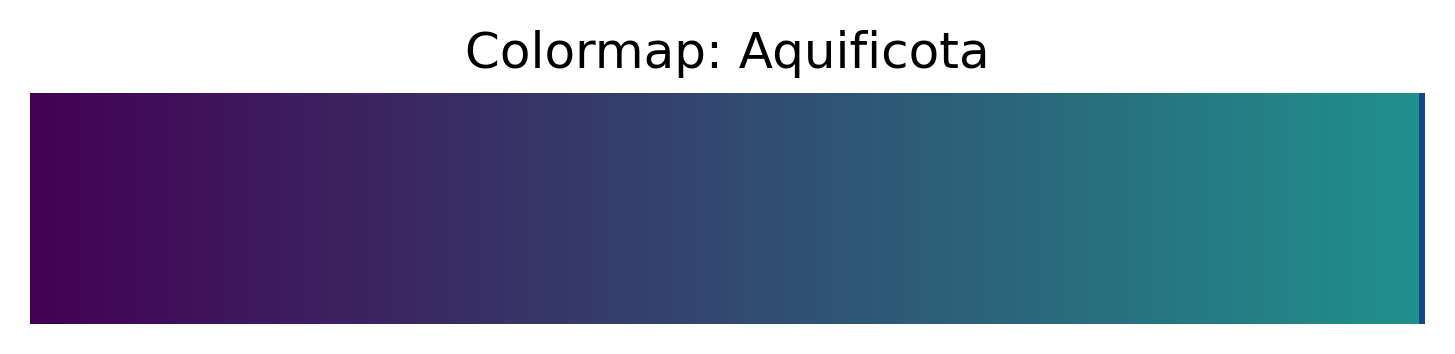

Bacillales


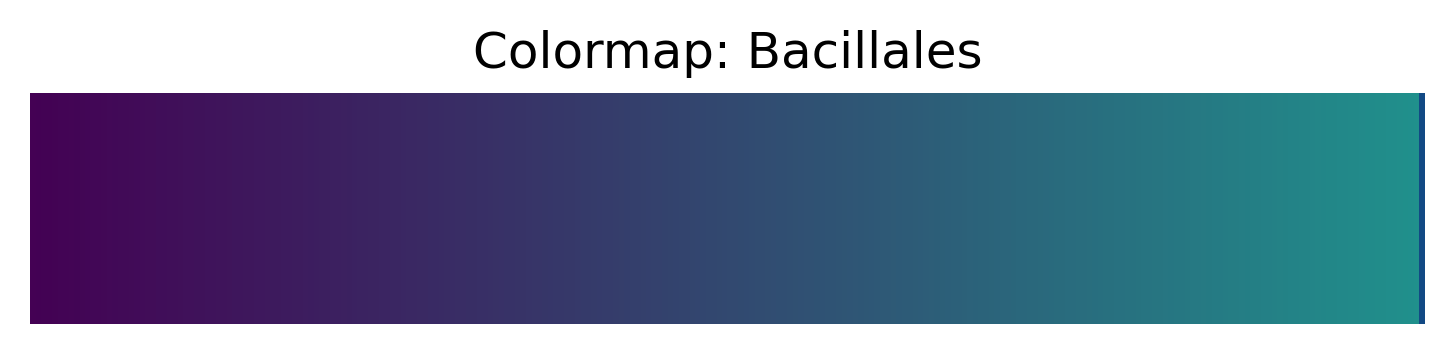

Caldisericia


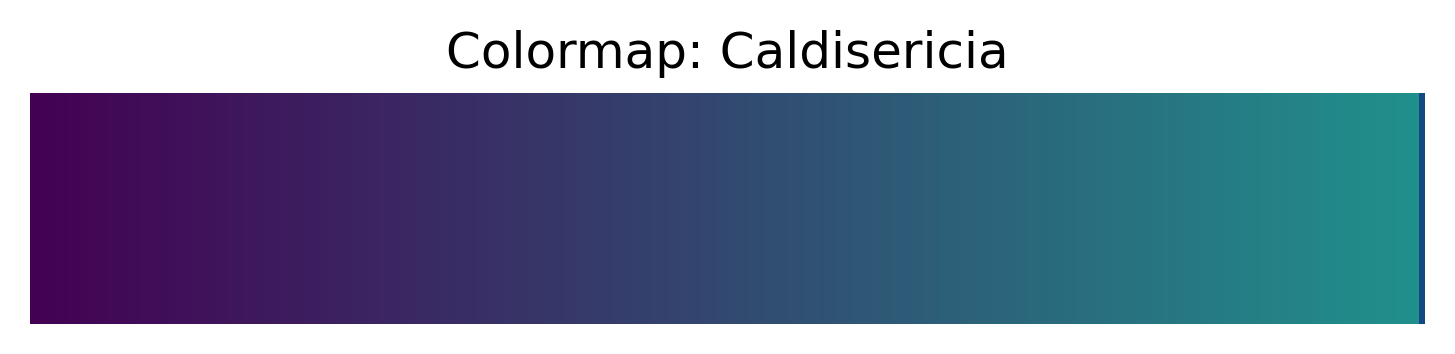

Chlamydia


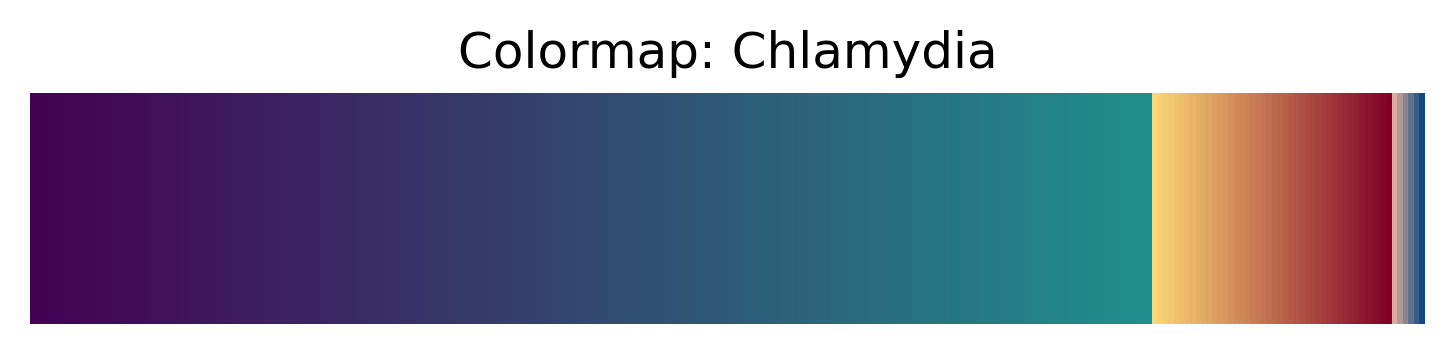

Cyano


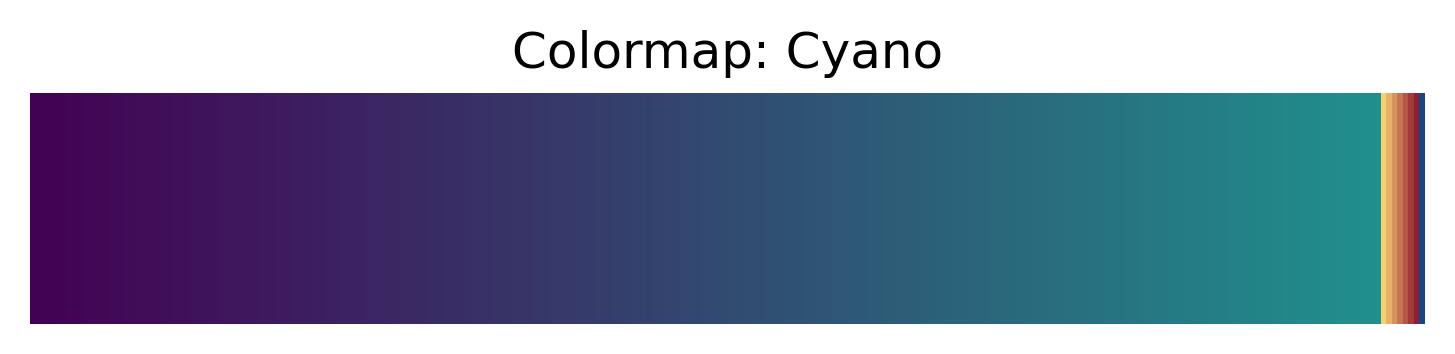

Neisseriaceae


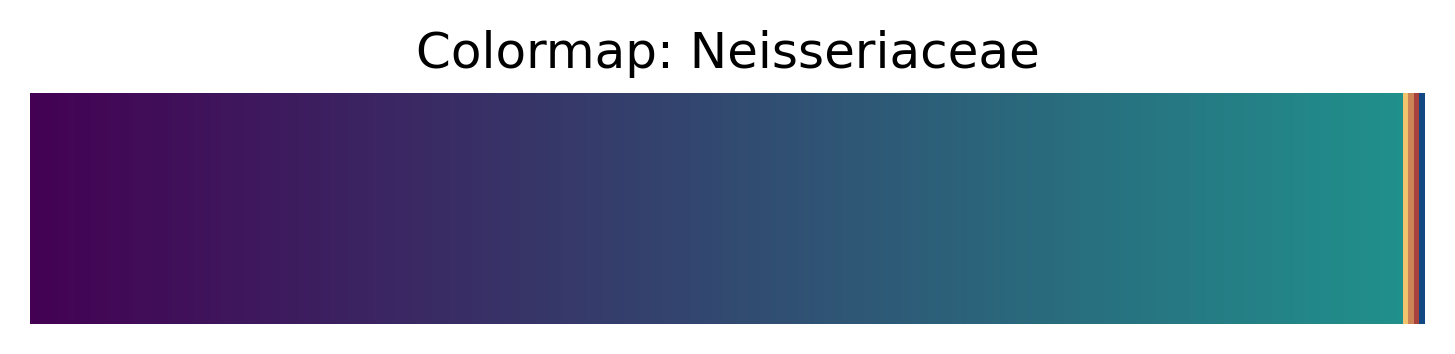

In [12]:
# Optinally: visualize the cmap
for name, (cmap, vmax) in cmap_dict.items():
    print(name)
    gradient = np.linspace(0, vmax, 1000).reshape(1, -1)
    fig, ax = plt.subplots(figsize=(6, 1))
    ax.imshow(gradient, aspect='auto', cmap=cmap)
    ax.set_axis_off()
    plt.title(f"Colormap: {name}")
    plt.show()


In [13]:
#
#def visualize_cmap_value(cmap, value, vmin=0.0, vmax=1.0, label=True):
#    """
#    cmap: str or Colormap (e.g. 'viridis')
#    value: scalar to visualize
#    vmin, vmax: normalization range
#    """
#    cmap_obj = mpl.cm.get_cmap(cmap) if isinstance(cmap, str) else cmap
#    norm = mpl.colors.Normalize(vmin=vmin, vmax=vmax)
#    rgba = cmap_obj(norm(value))
#
#    fig, ax = plt.subplots(figsize=(4, 1))
#    ax.imshow(np.array([[rgba]]), aspect='auto')
#    ax.set_axis_off()
#
#    if label:
#        ax.set_title(f"{cmap_obj.name}: value={value}, rgba={tuple(round(x, 3) for x in rgba)}", fontsize=10)
#
#    plt.show()
#    return rgba
#
#name = 'Neisseriaceae'
#cmap, vmax = cmap_dict[name]
#val = 0.896059257      # the limit value between blue and yellow
#    #   0.8984987730414541
#val = 0.8984987730414541
#
#print(vmax)
#visualize_cmap_value(cmap, val, vmin=0, vmax=vmax)

## Grid search and heatmaps on (one to three) k-mers

### One k-mer

Aquificota


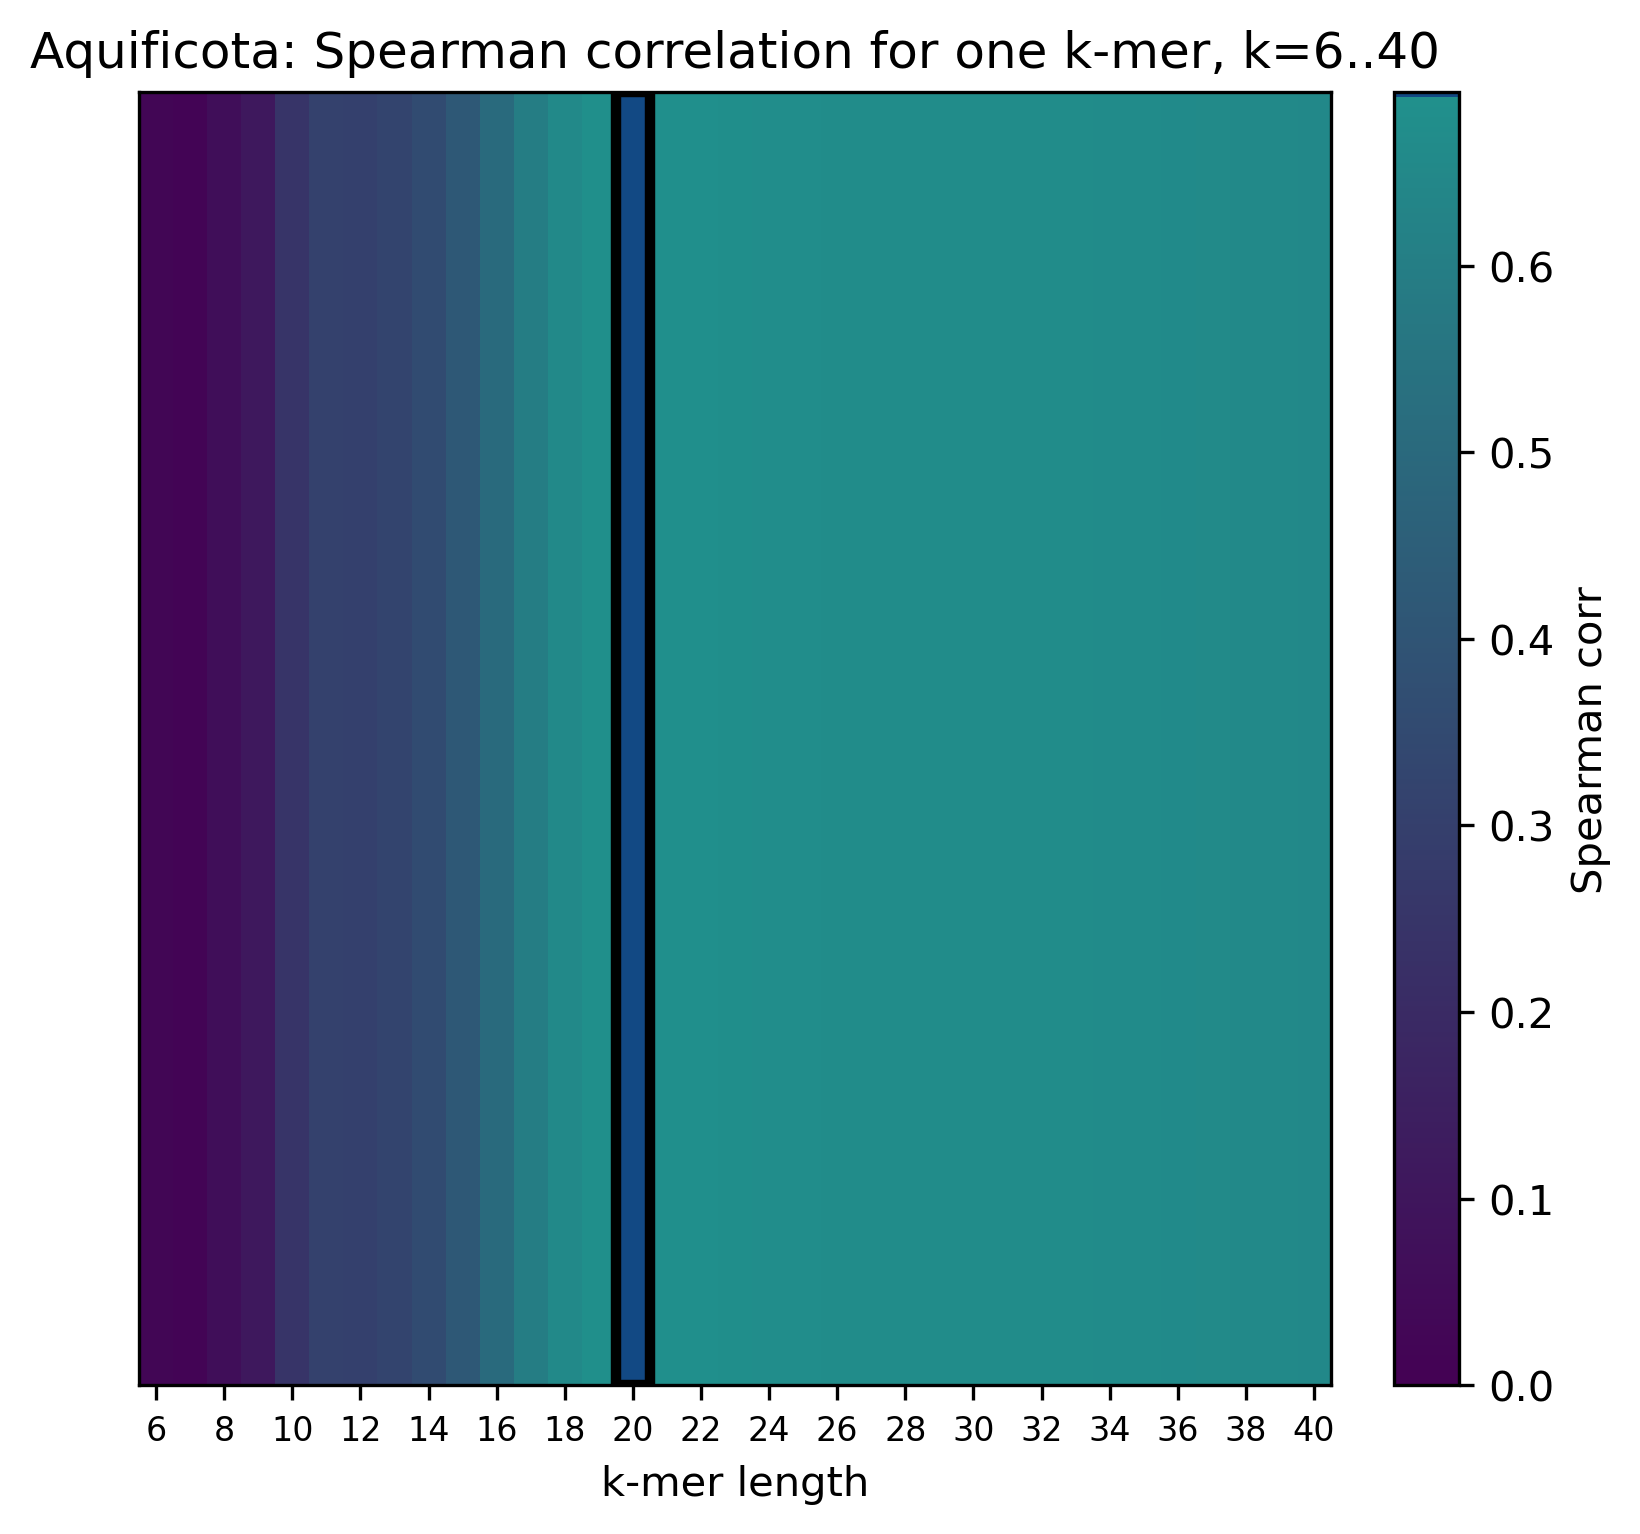


Bacillales


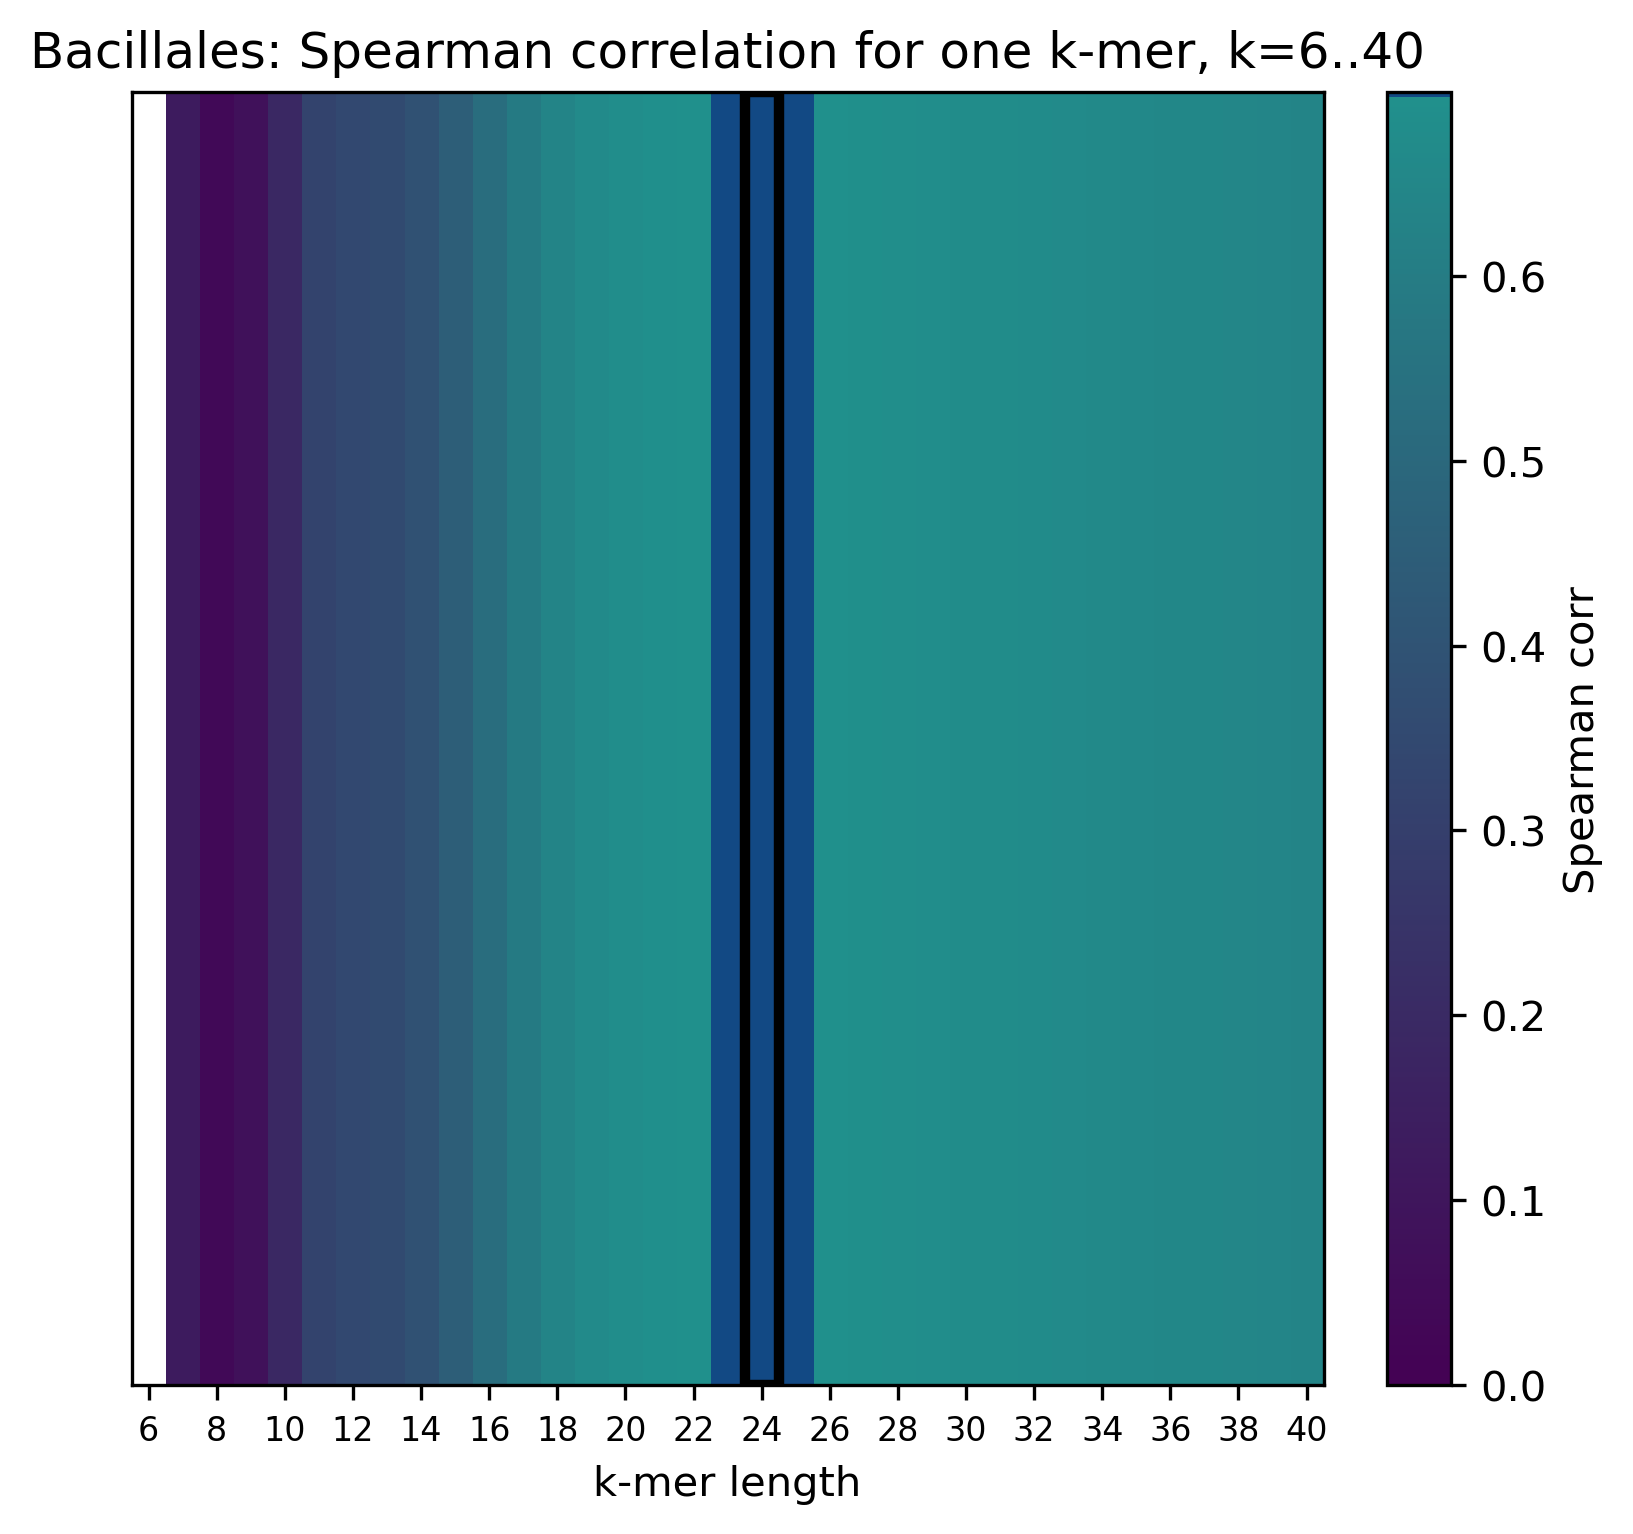


Caldisericia


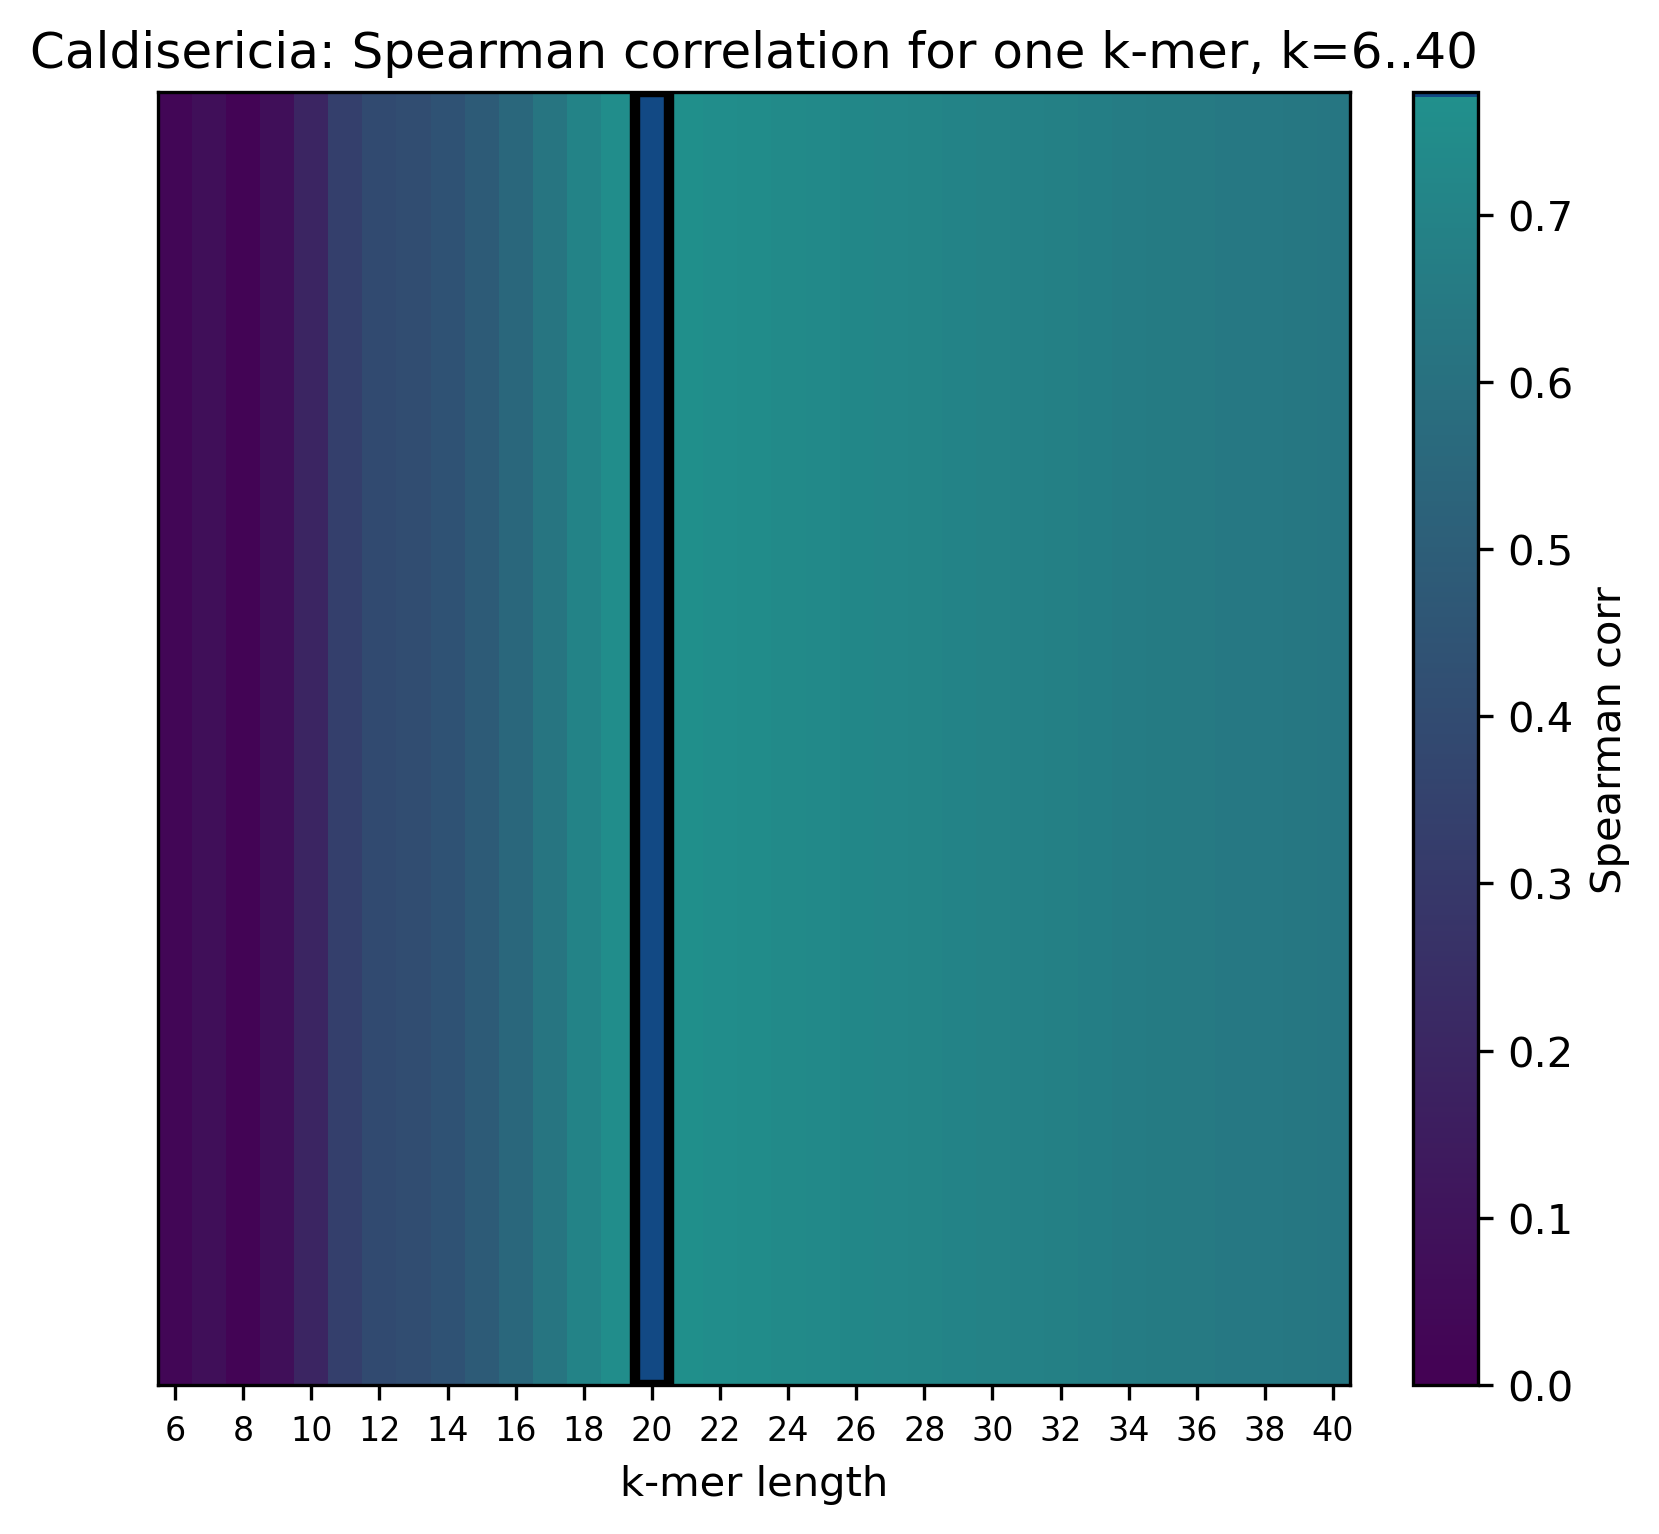


Chlamydia


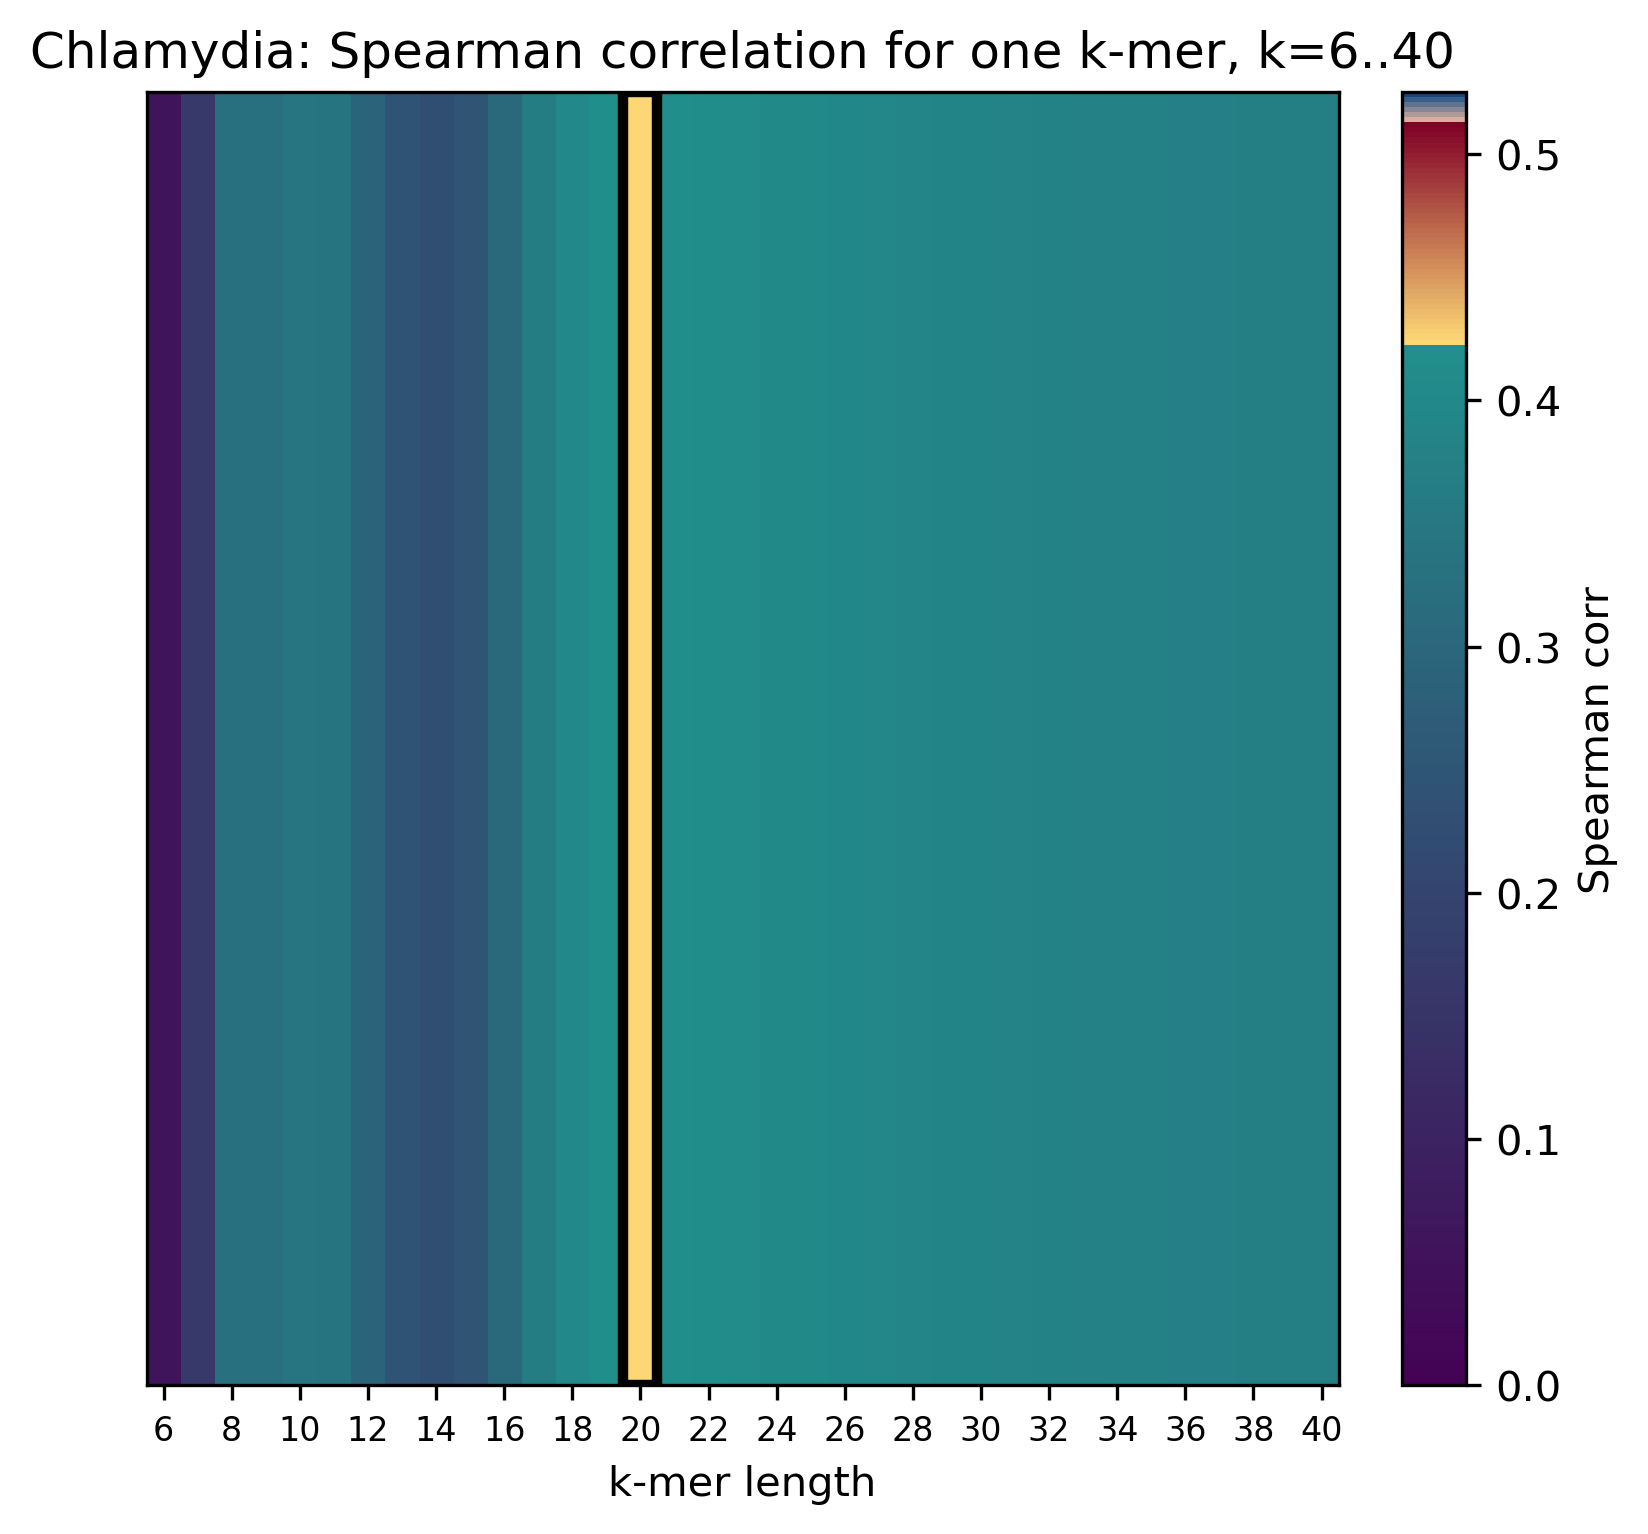


Cyano


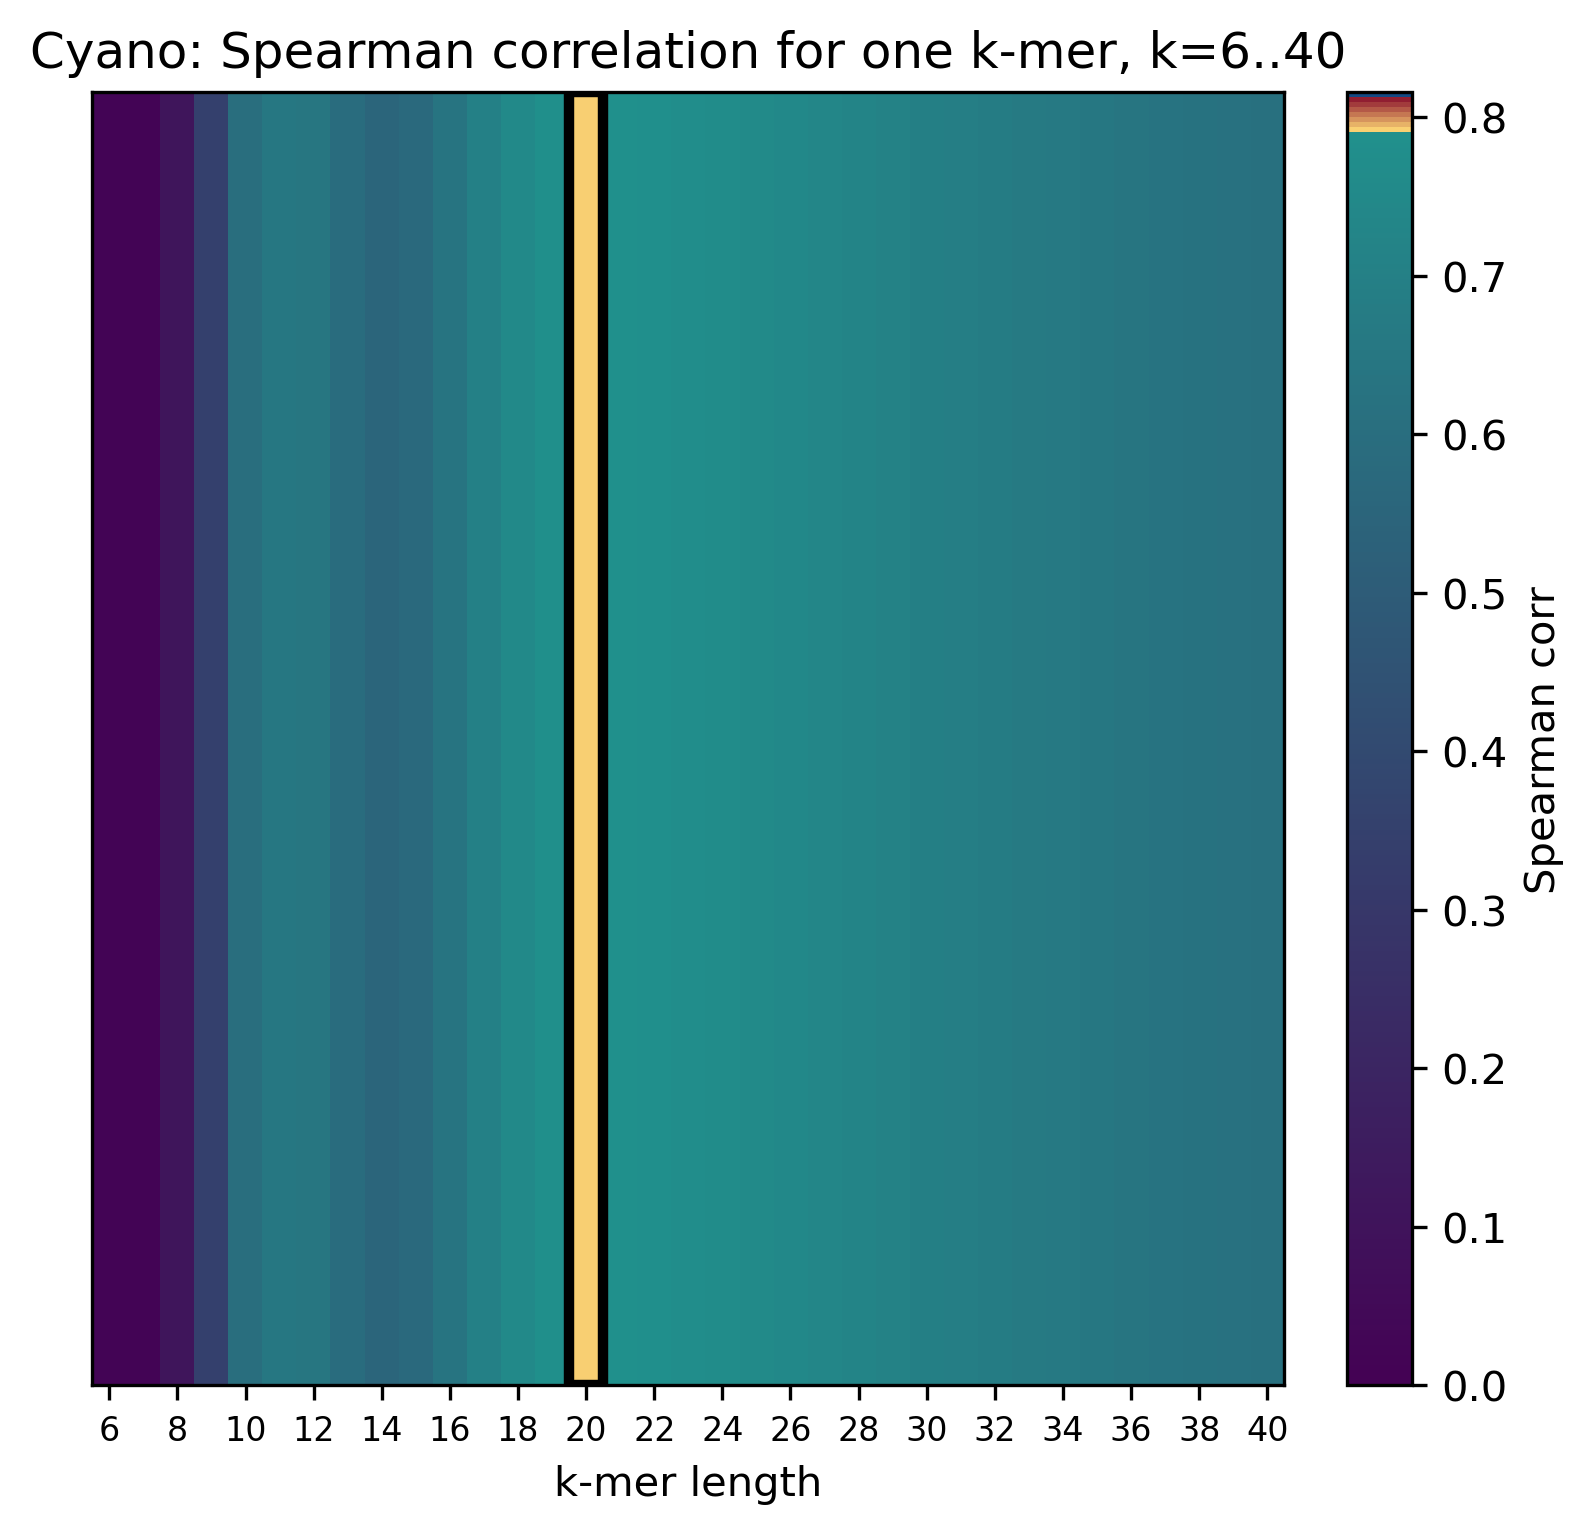


Neisseriaceae


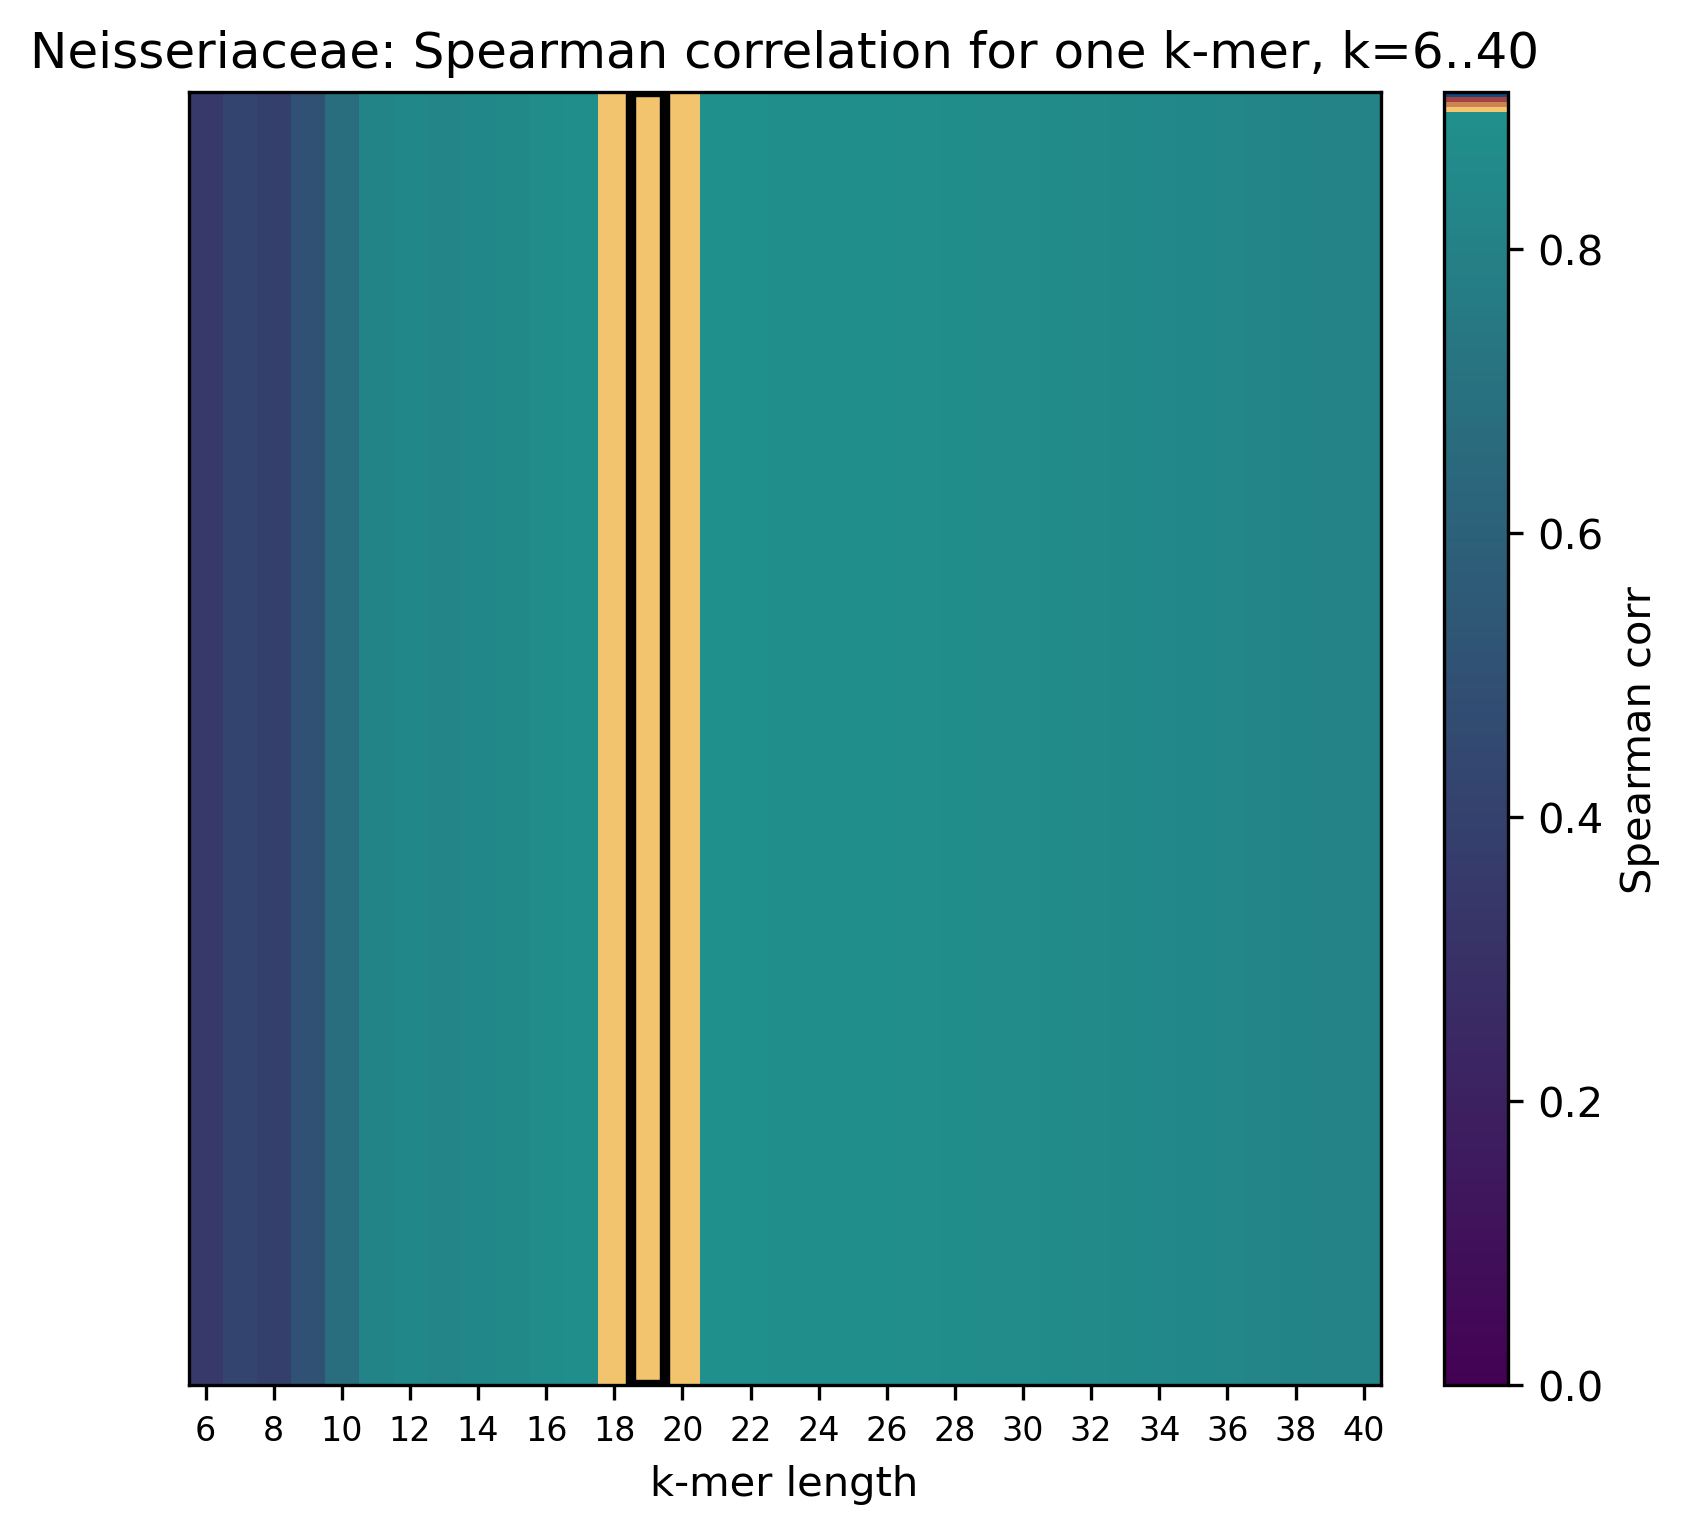

In [14]:
# Run full grid search
for name, df in datasets_1k:
    print(name)
    ok_k_mer.plot_1k_colorbar_corr(name, df, k_low=6, k_high=40, cmap_vmax=cmap_dict[name])
    print()


### Two k-mers


Aquificota
(array([28]), array([14])) 0.6930305020275189


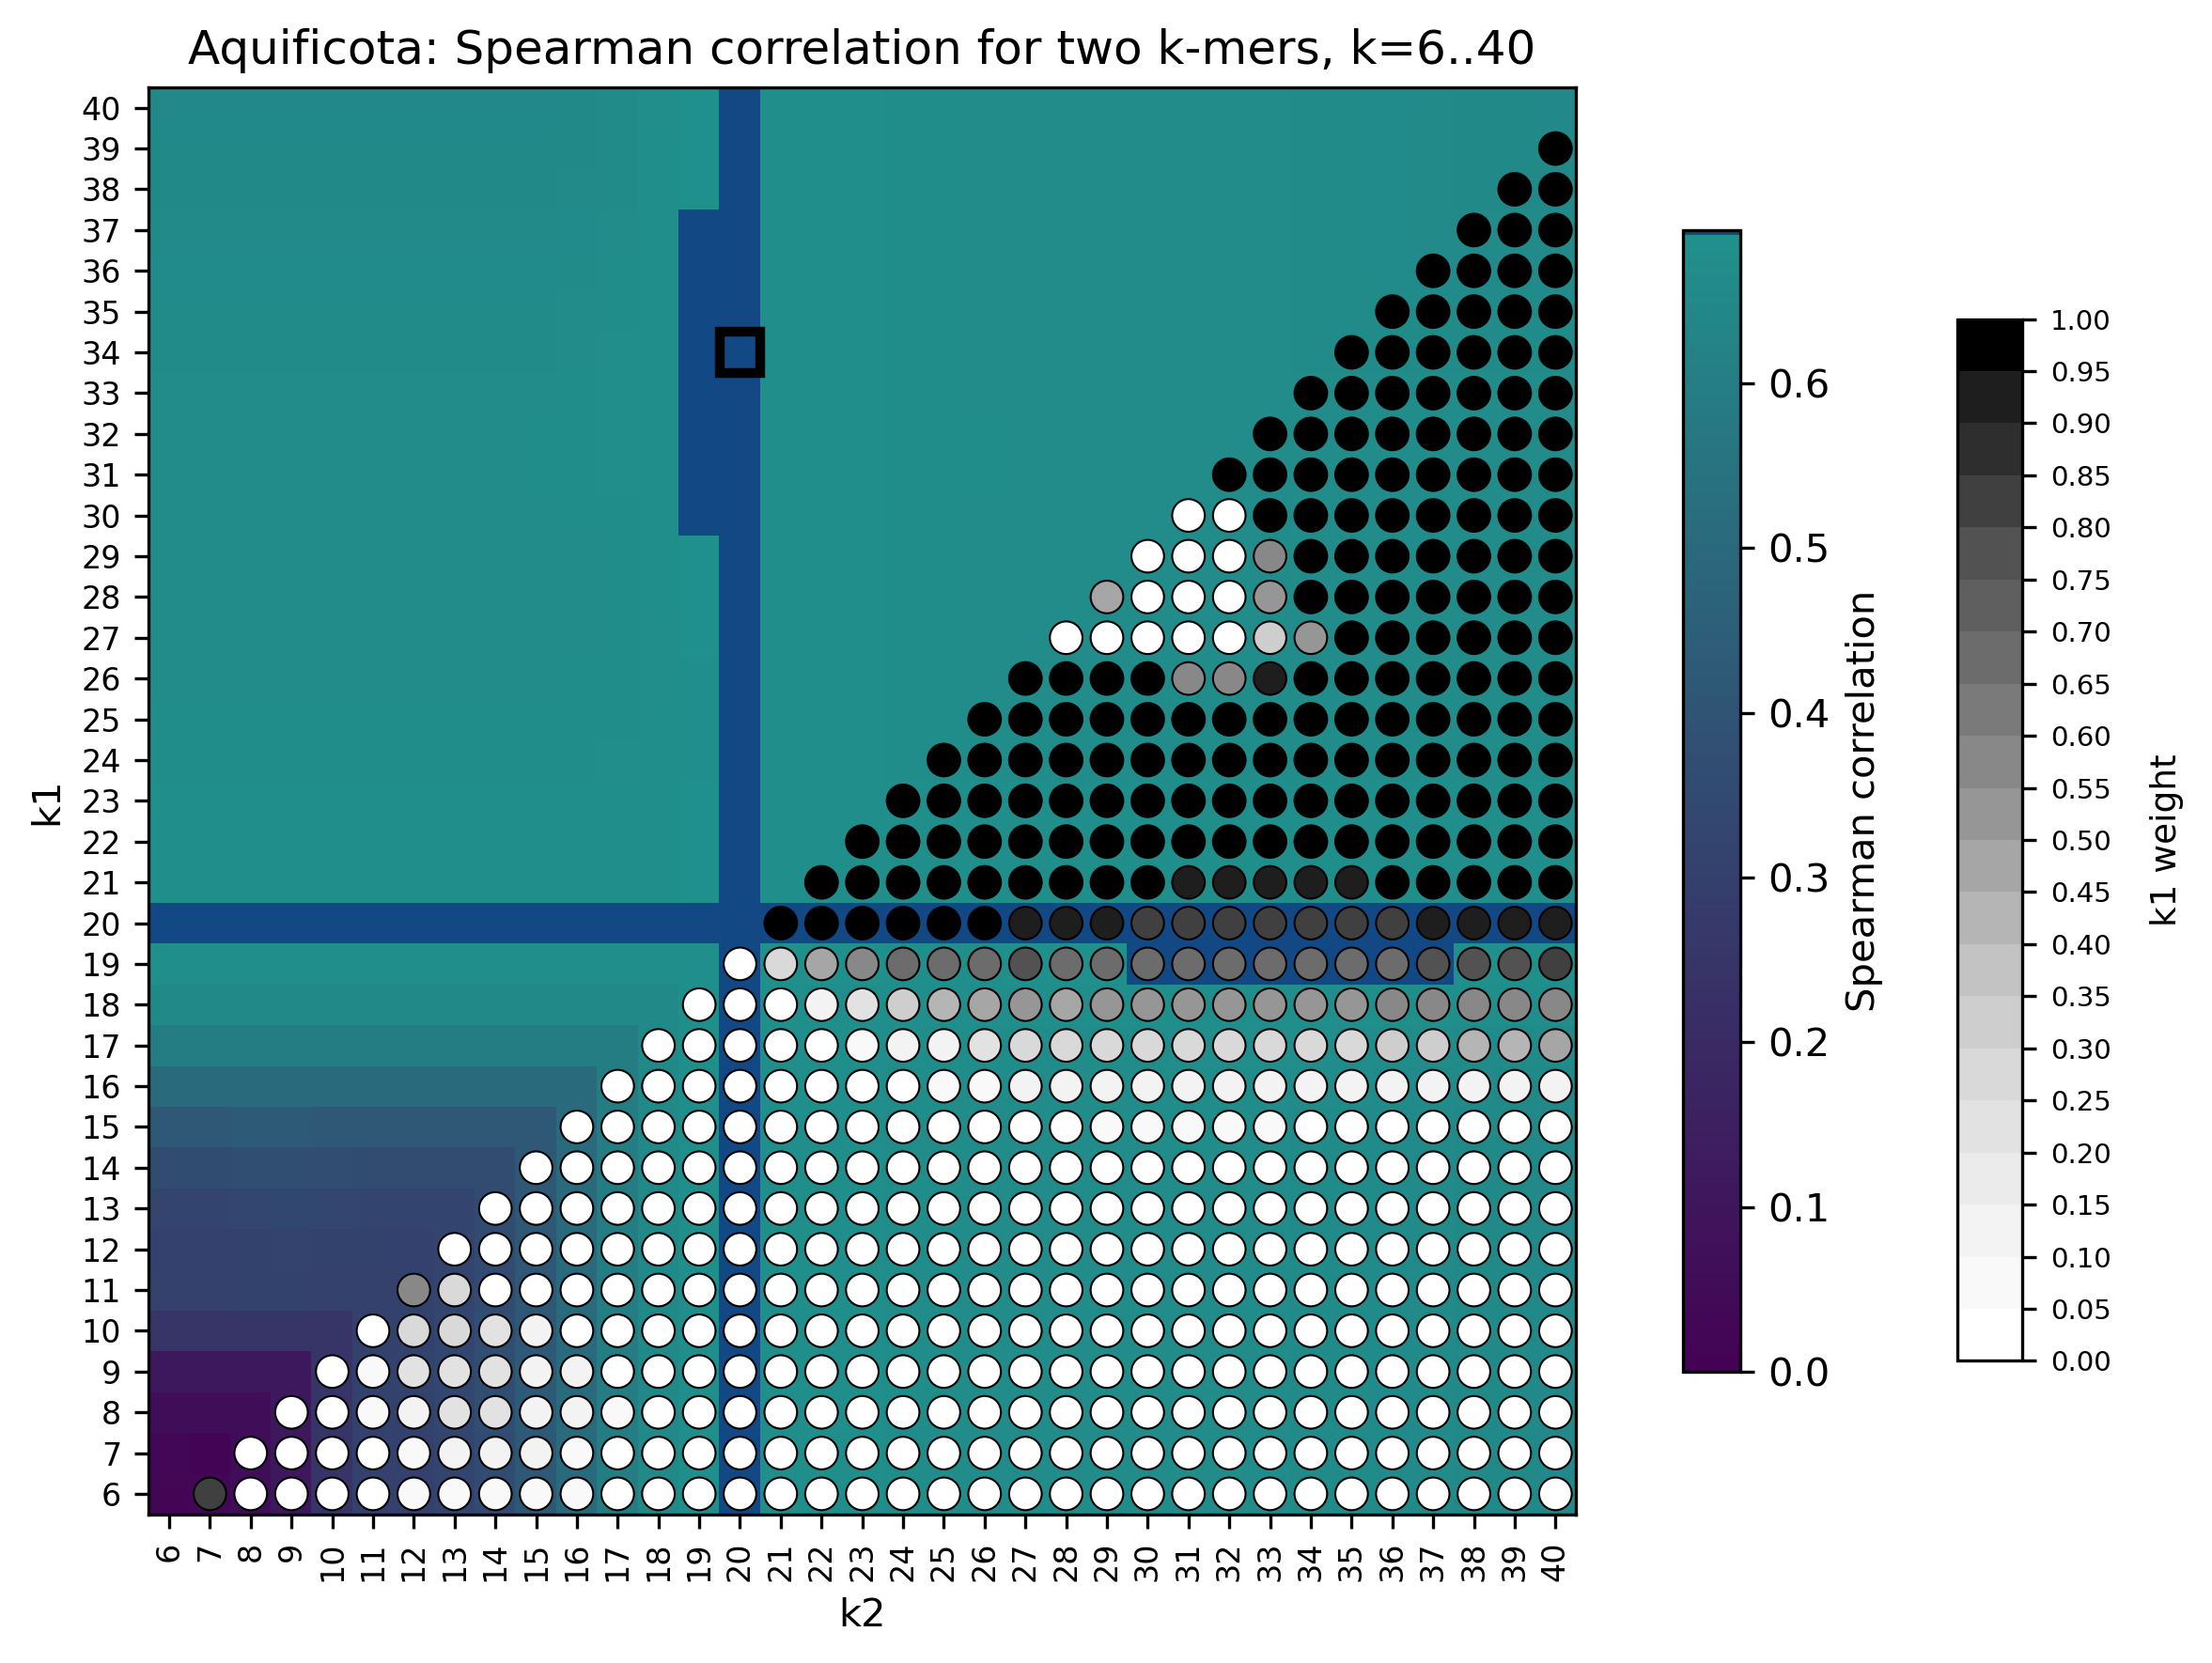


Bacillales
(array([ 1, 17]), array([17,  1])) 0.6993156409948573


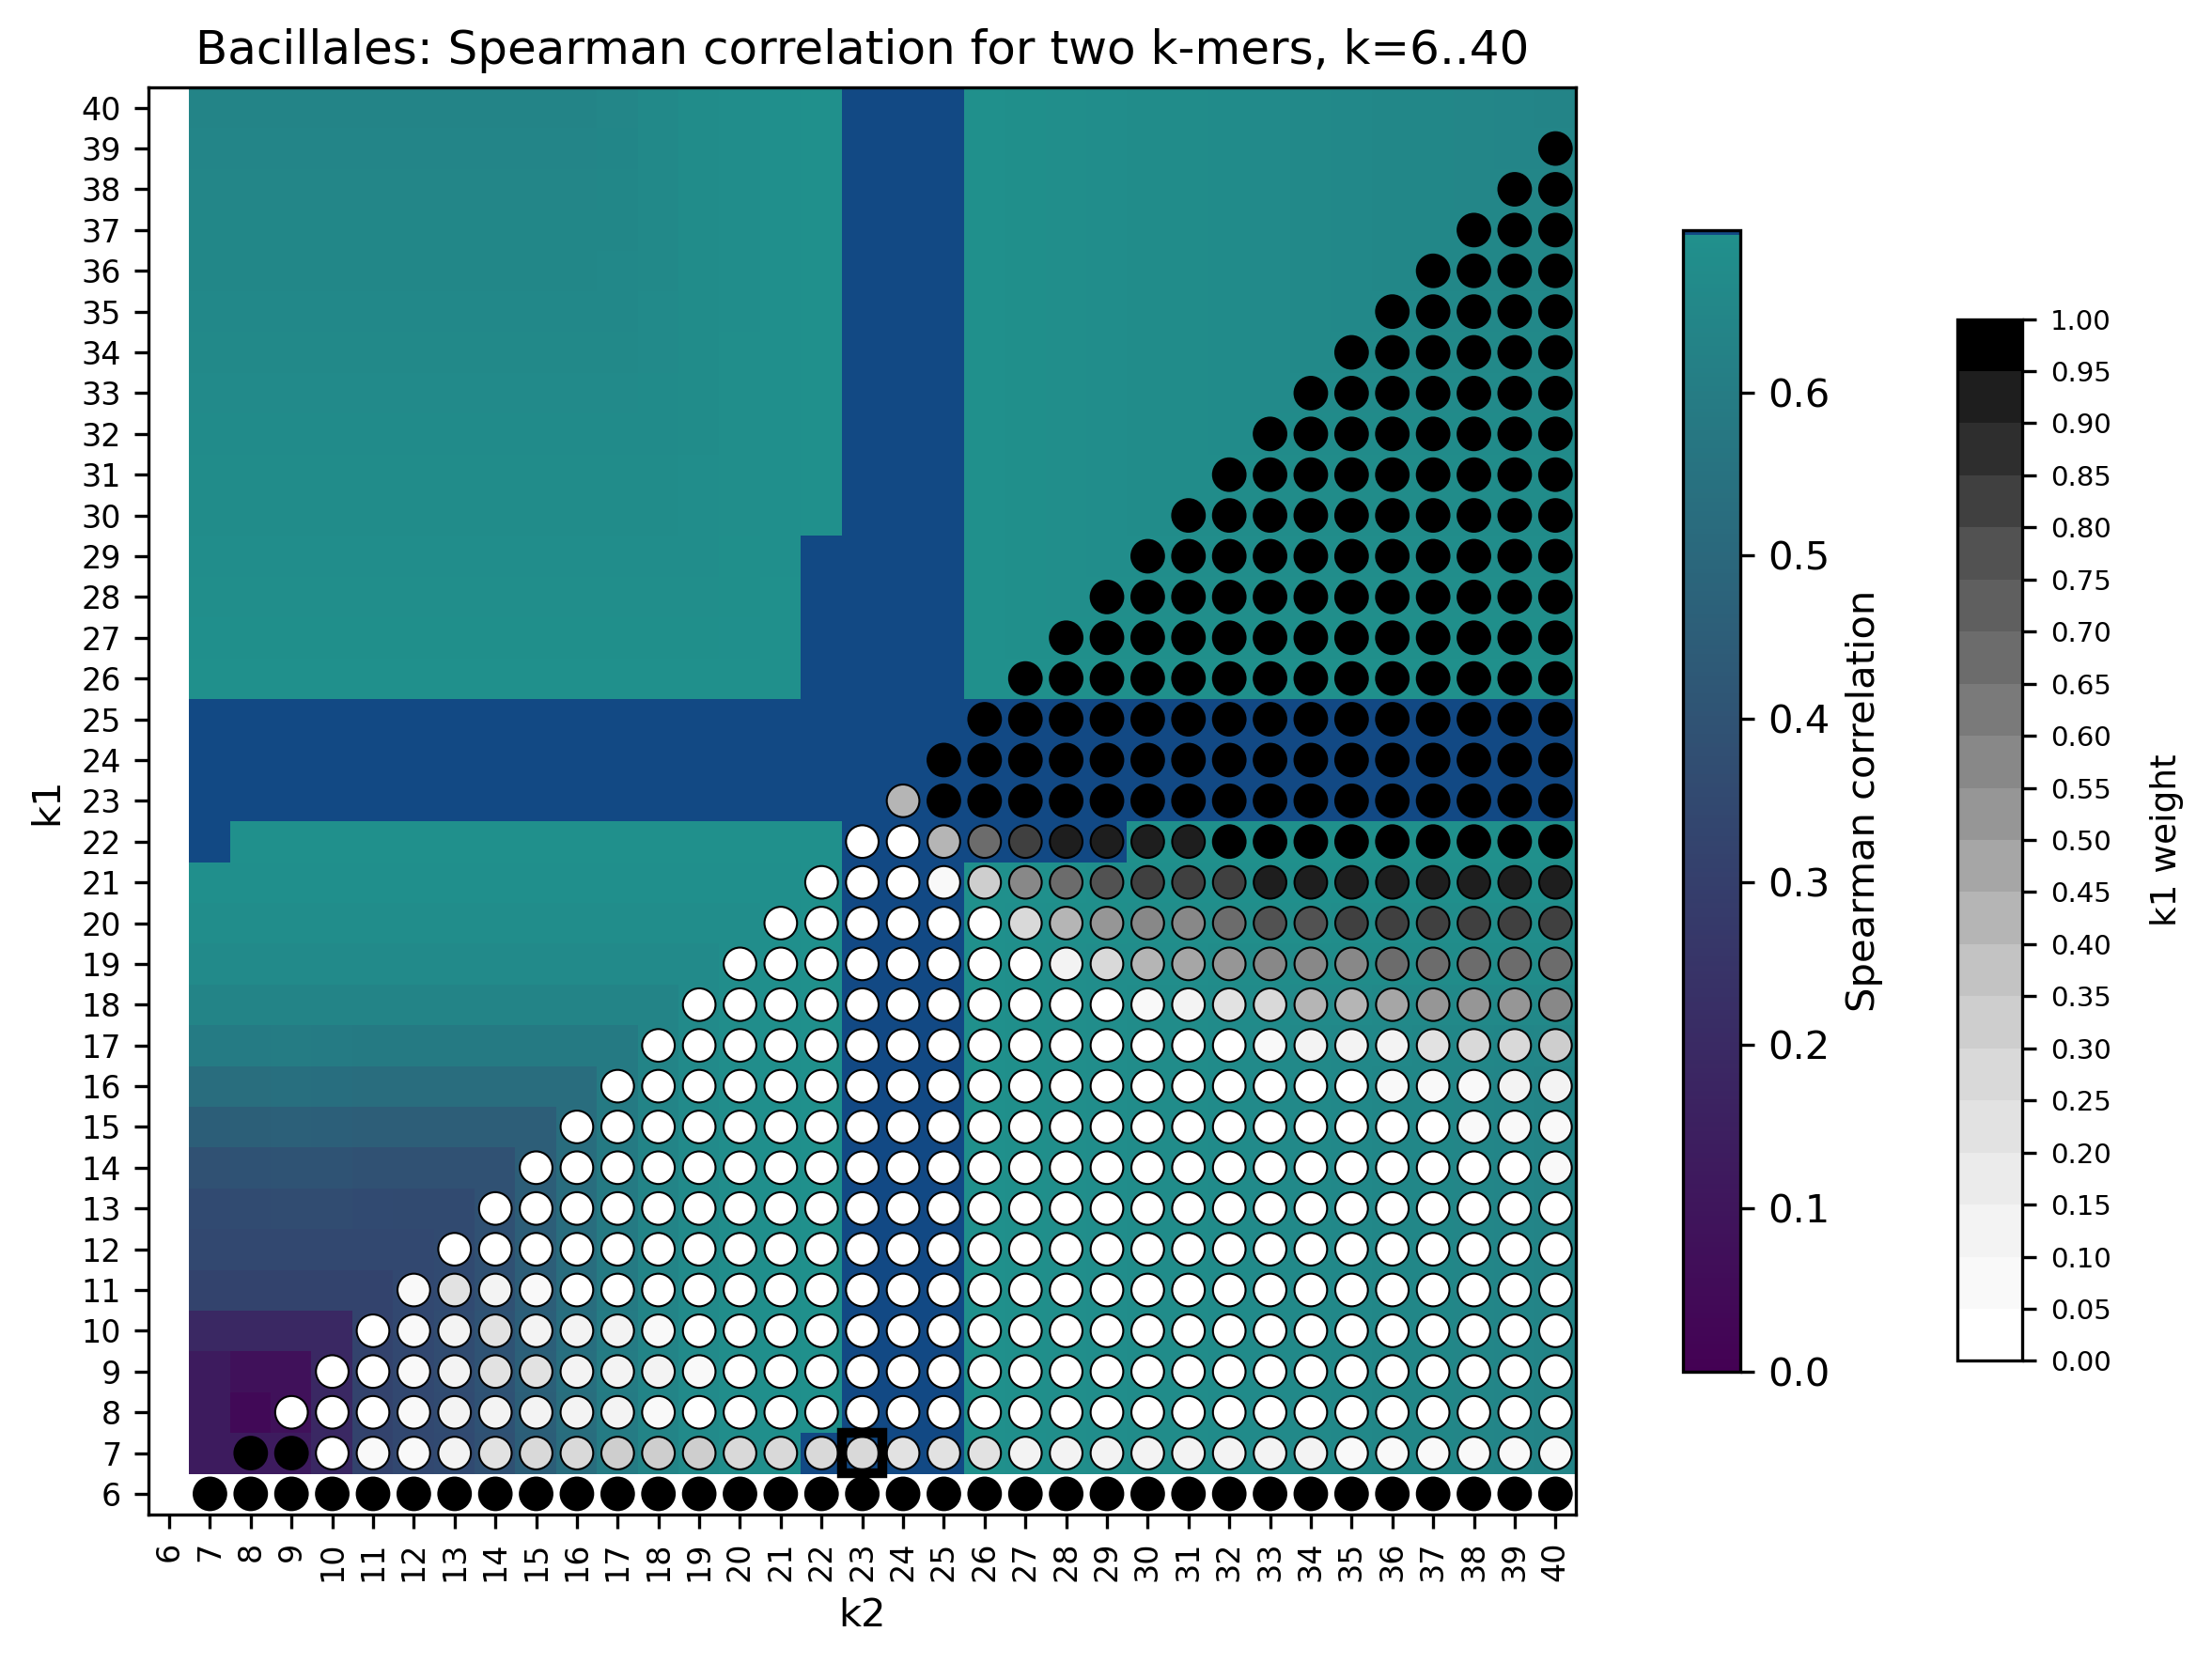


Caldisericia
(array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 14, 14,
       14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14,
       14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34]), array([14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14,  0,  1,  2,
        3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19,
       20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33, 34, 14, 14,
       14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14, 14,
       14])) 0.7732939230754757


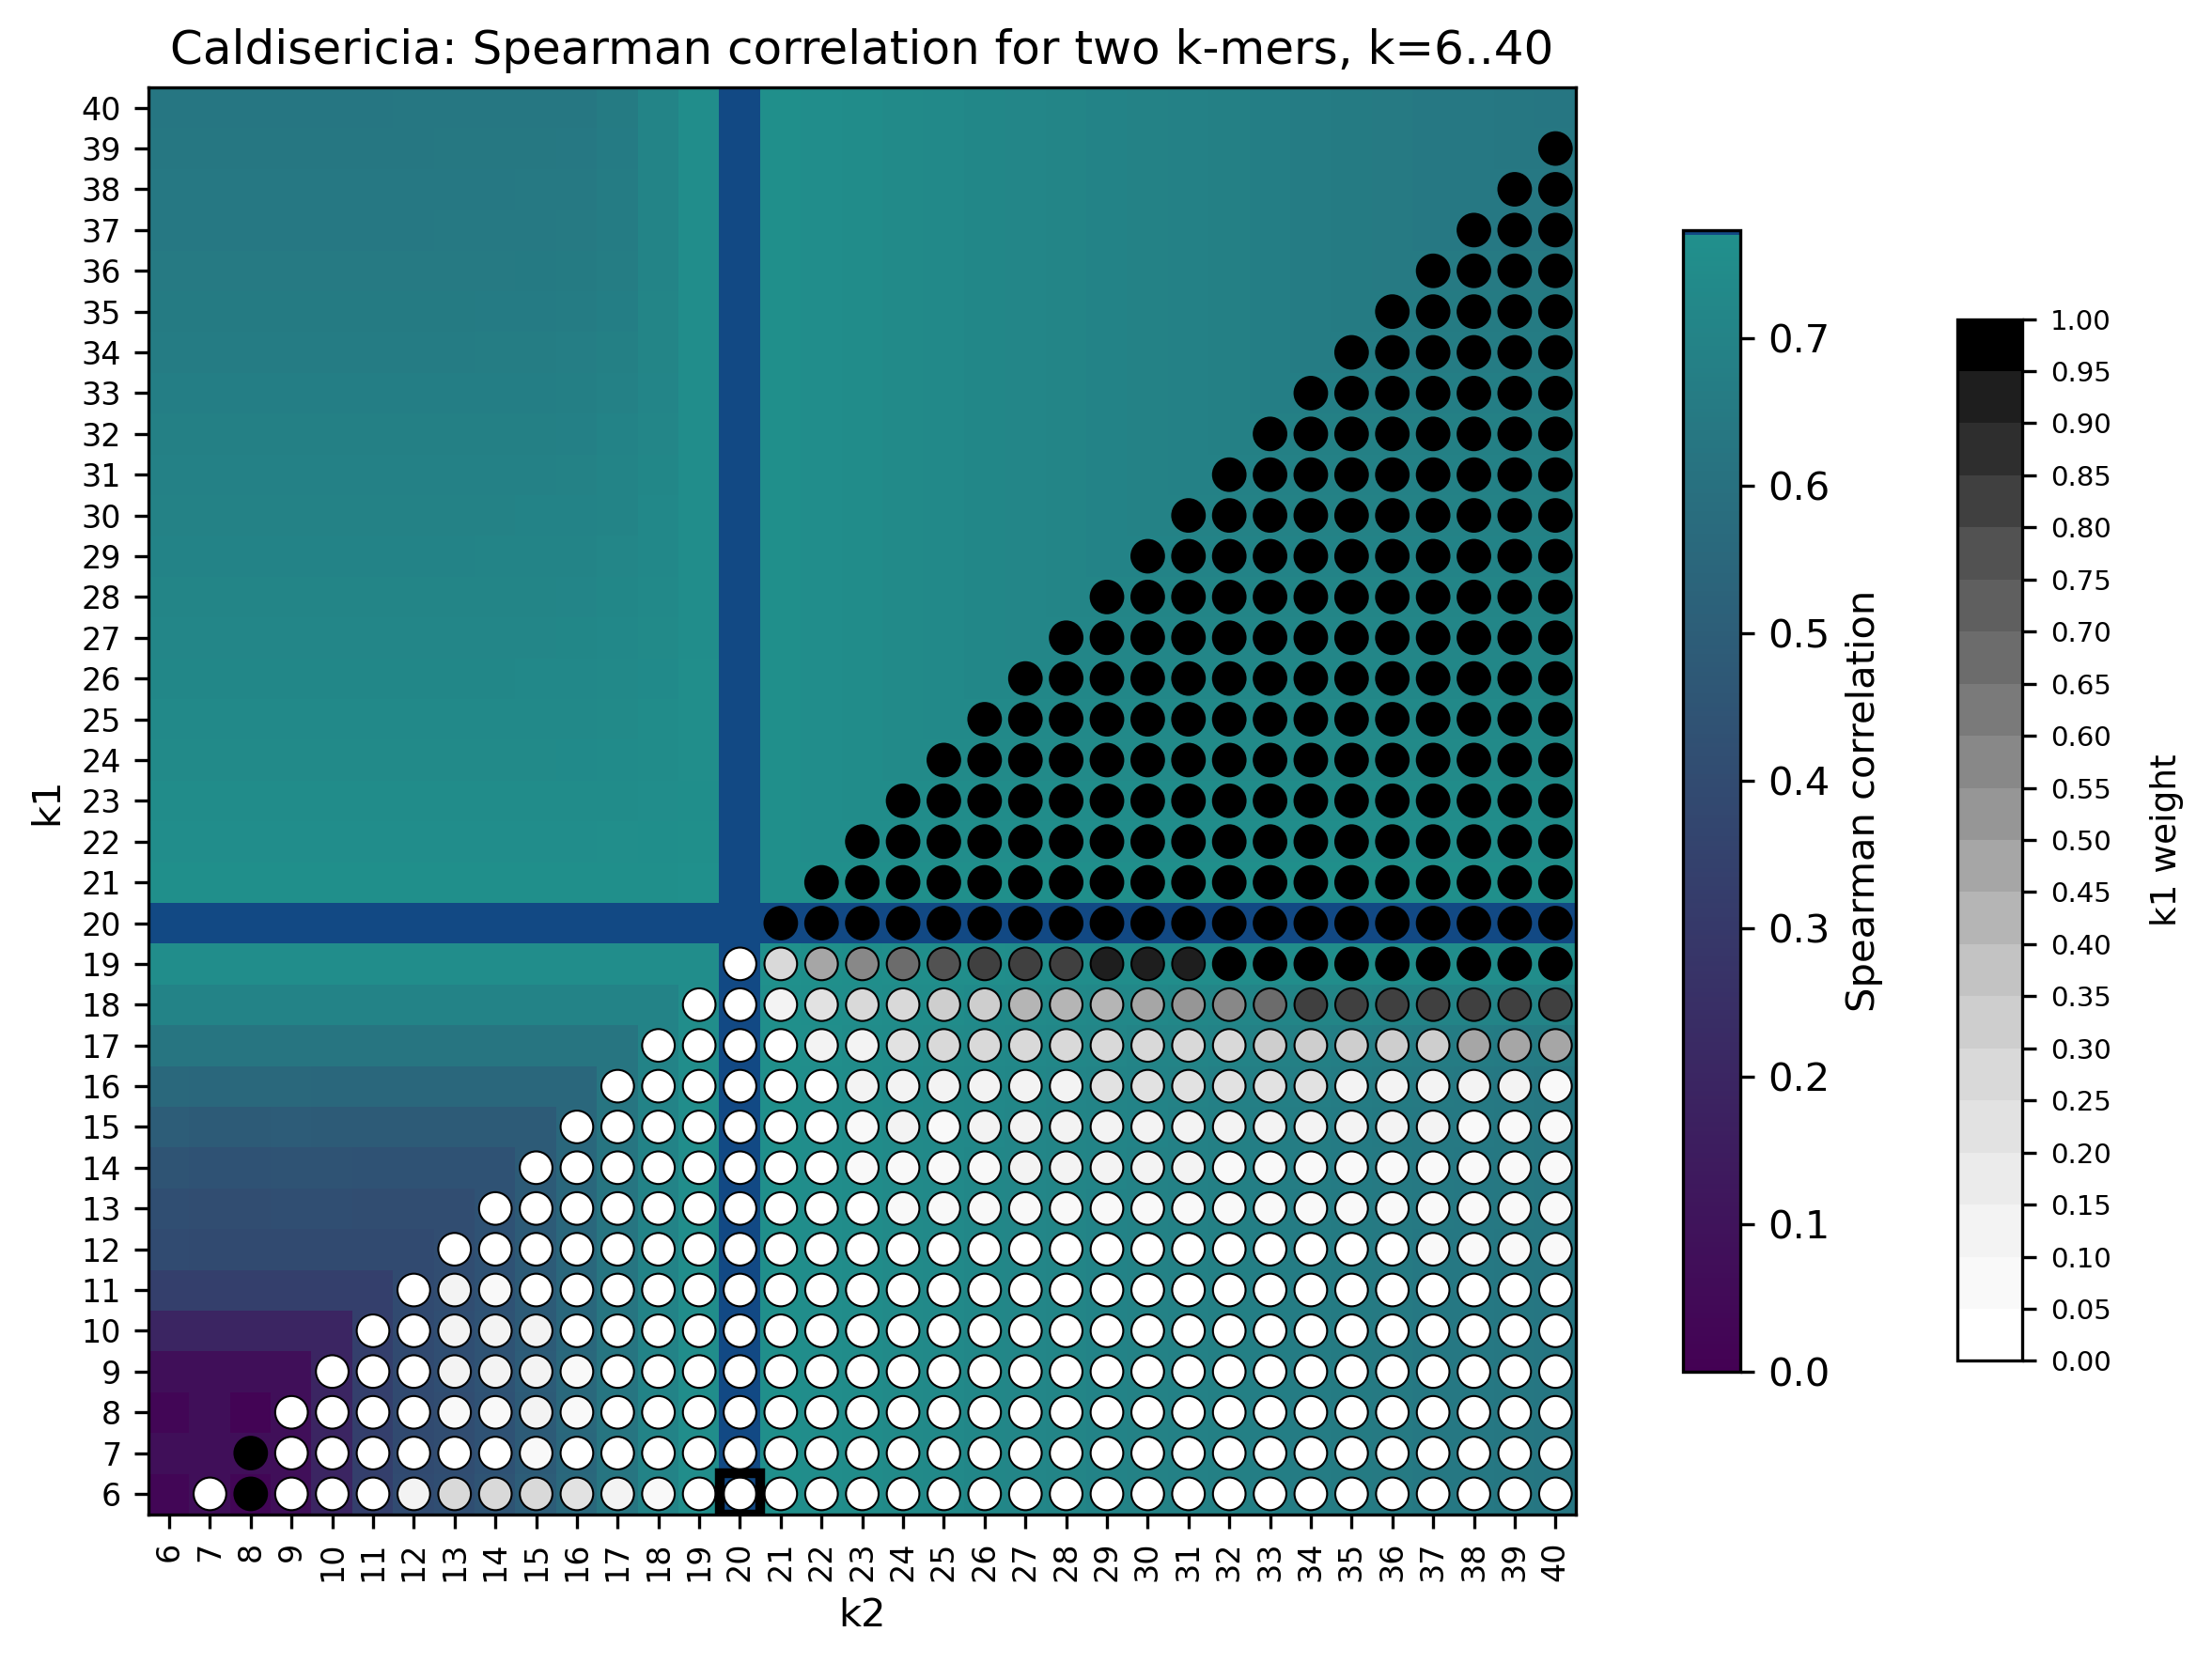


Chlamydia
(array([3]), array([12])) 0.5132143691921338


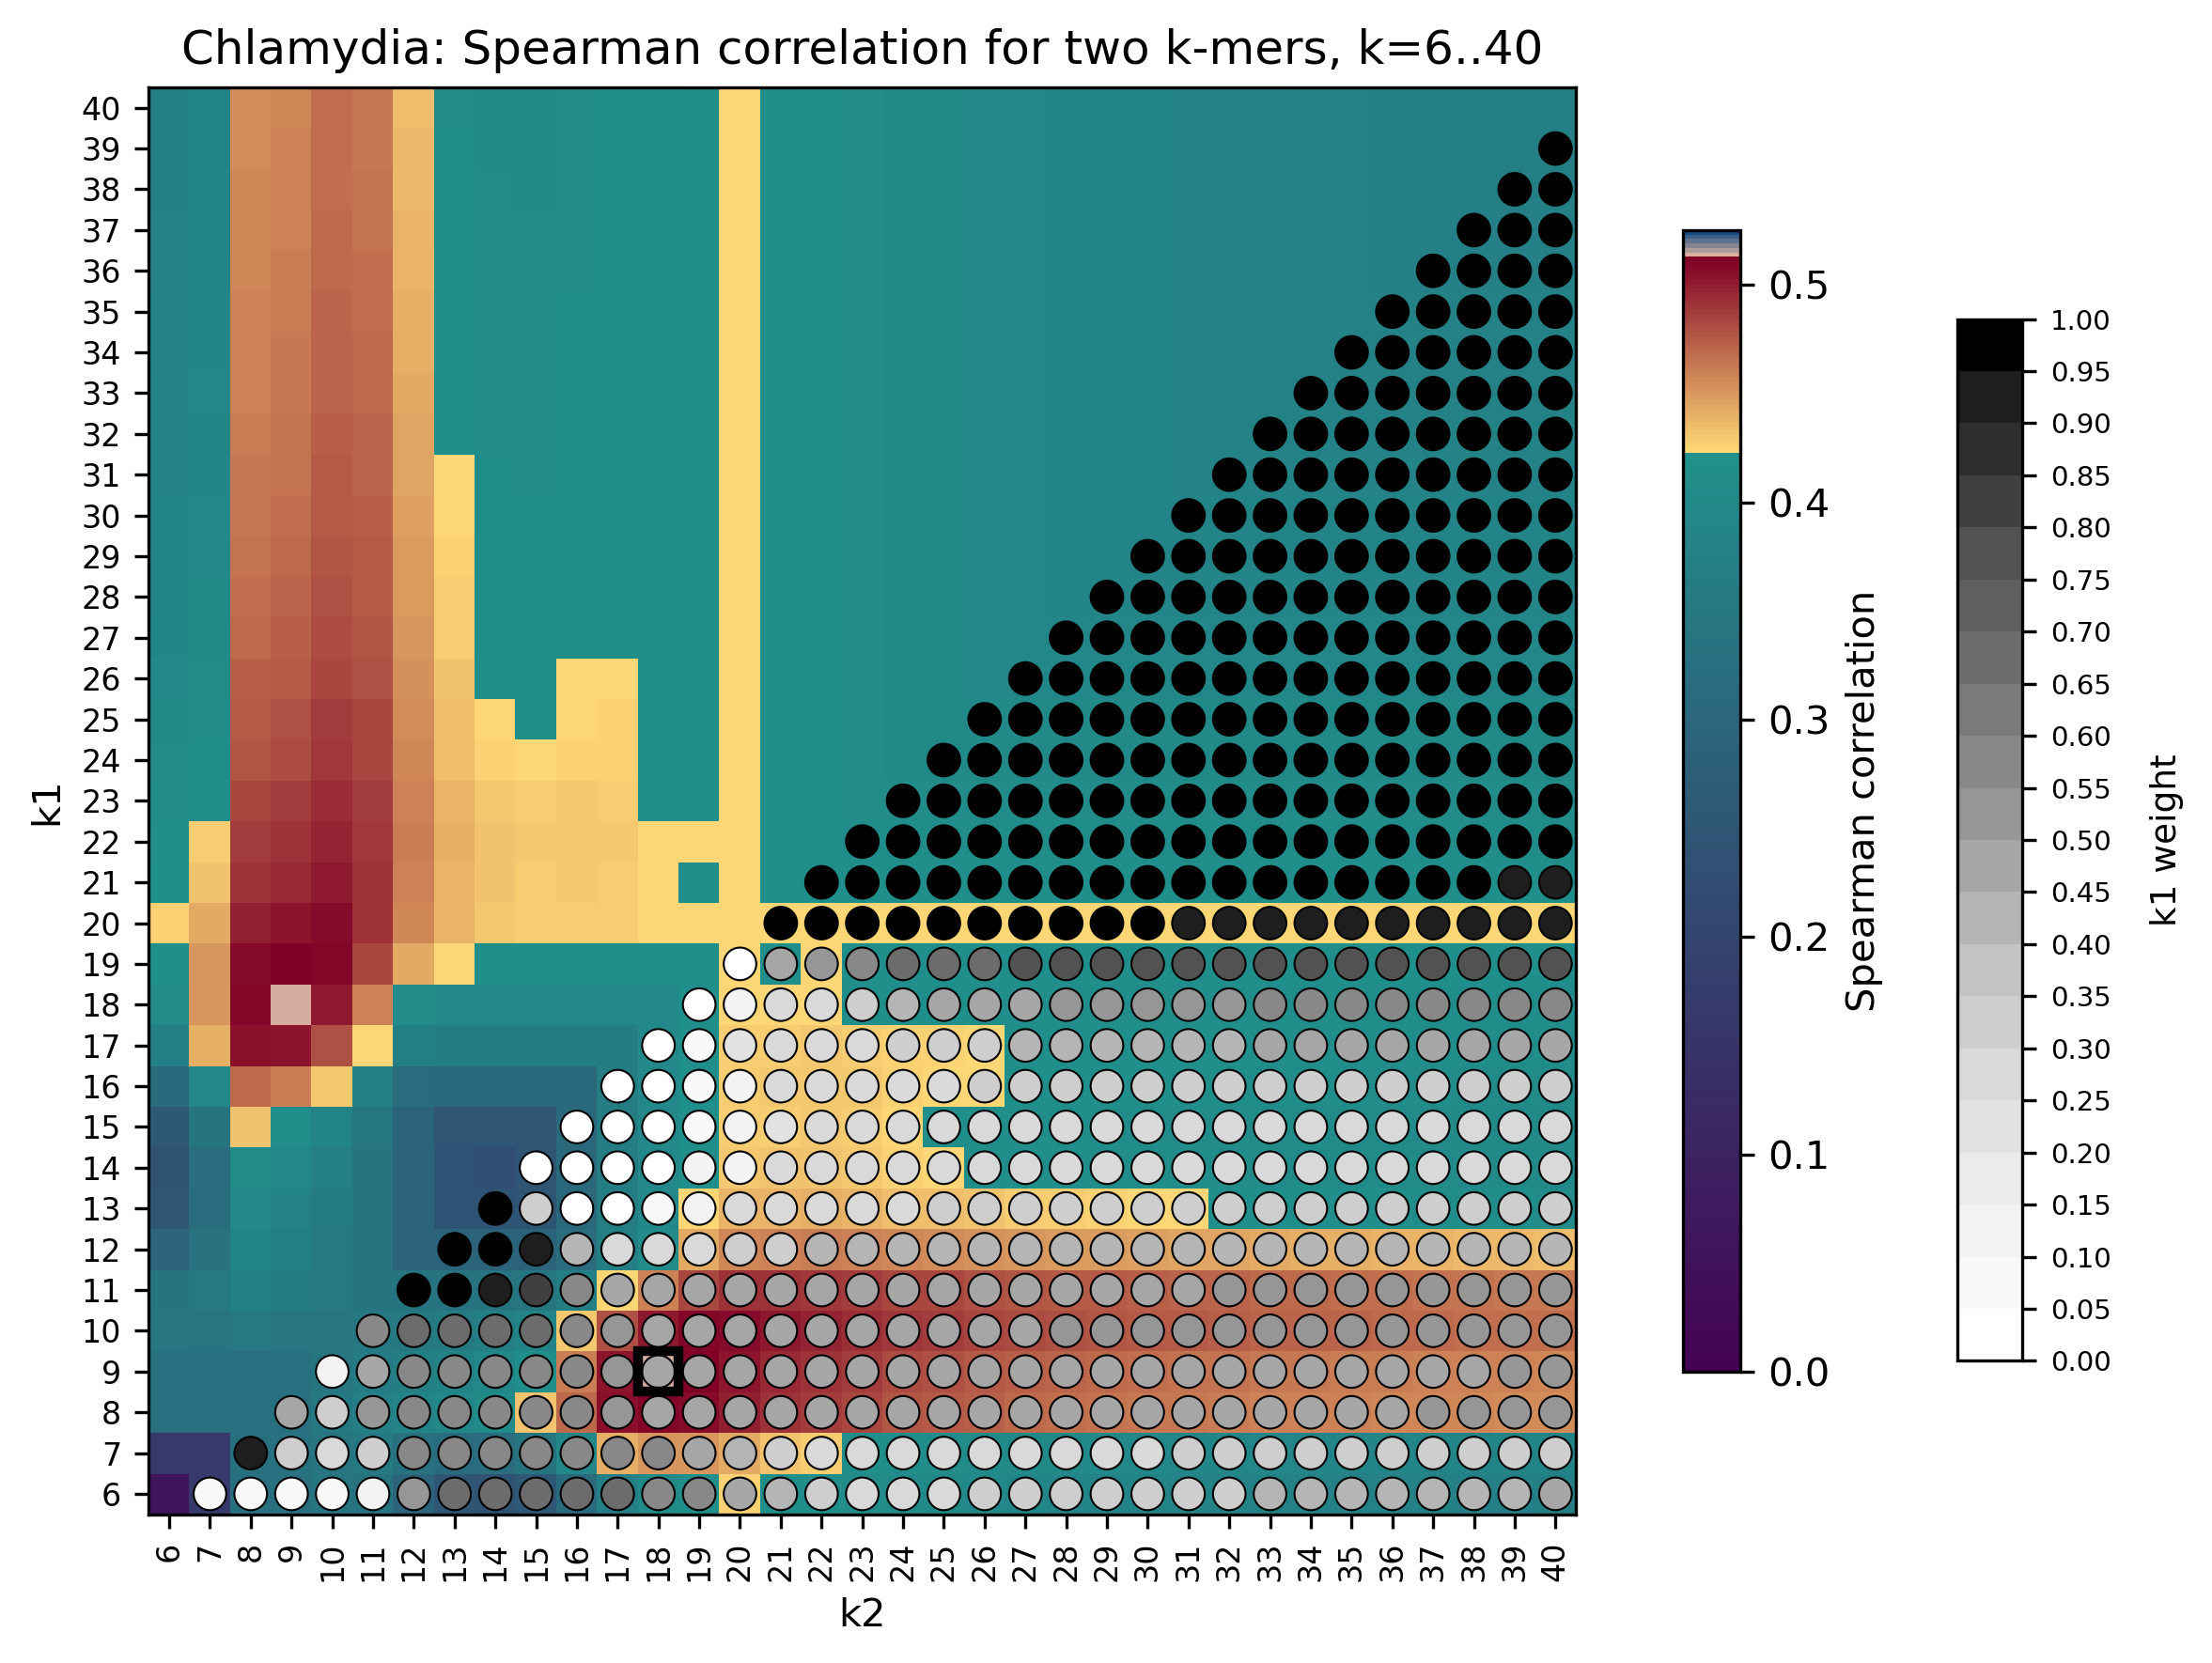


Cyano
(array([ 4, 14]), array([14,  4])) 0.8159030261740672


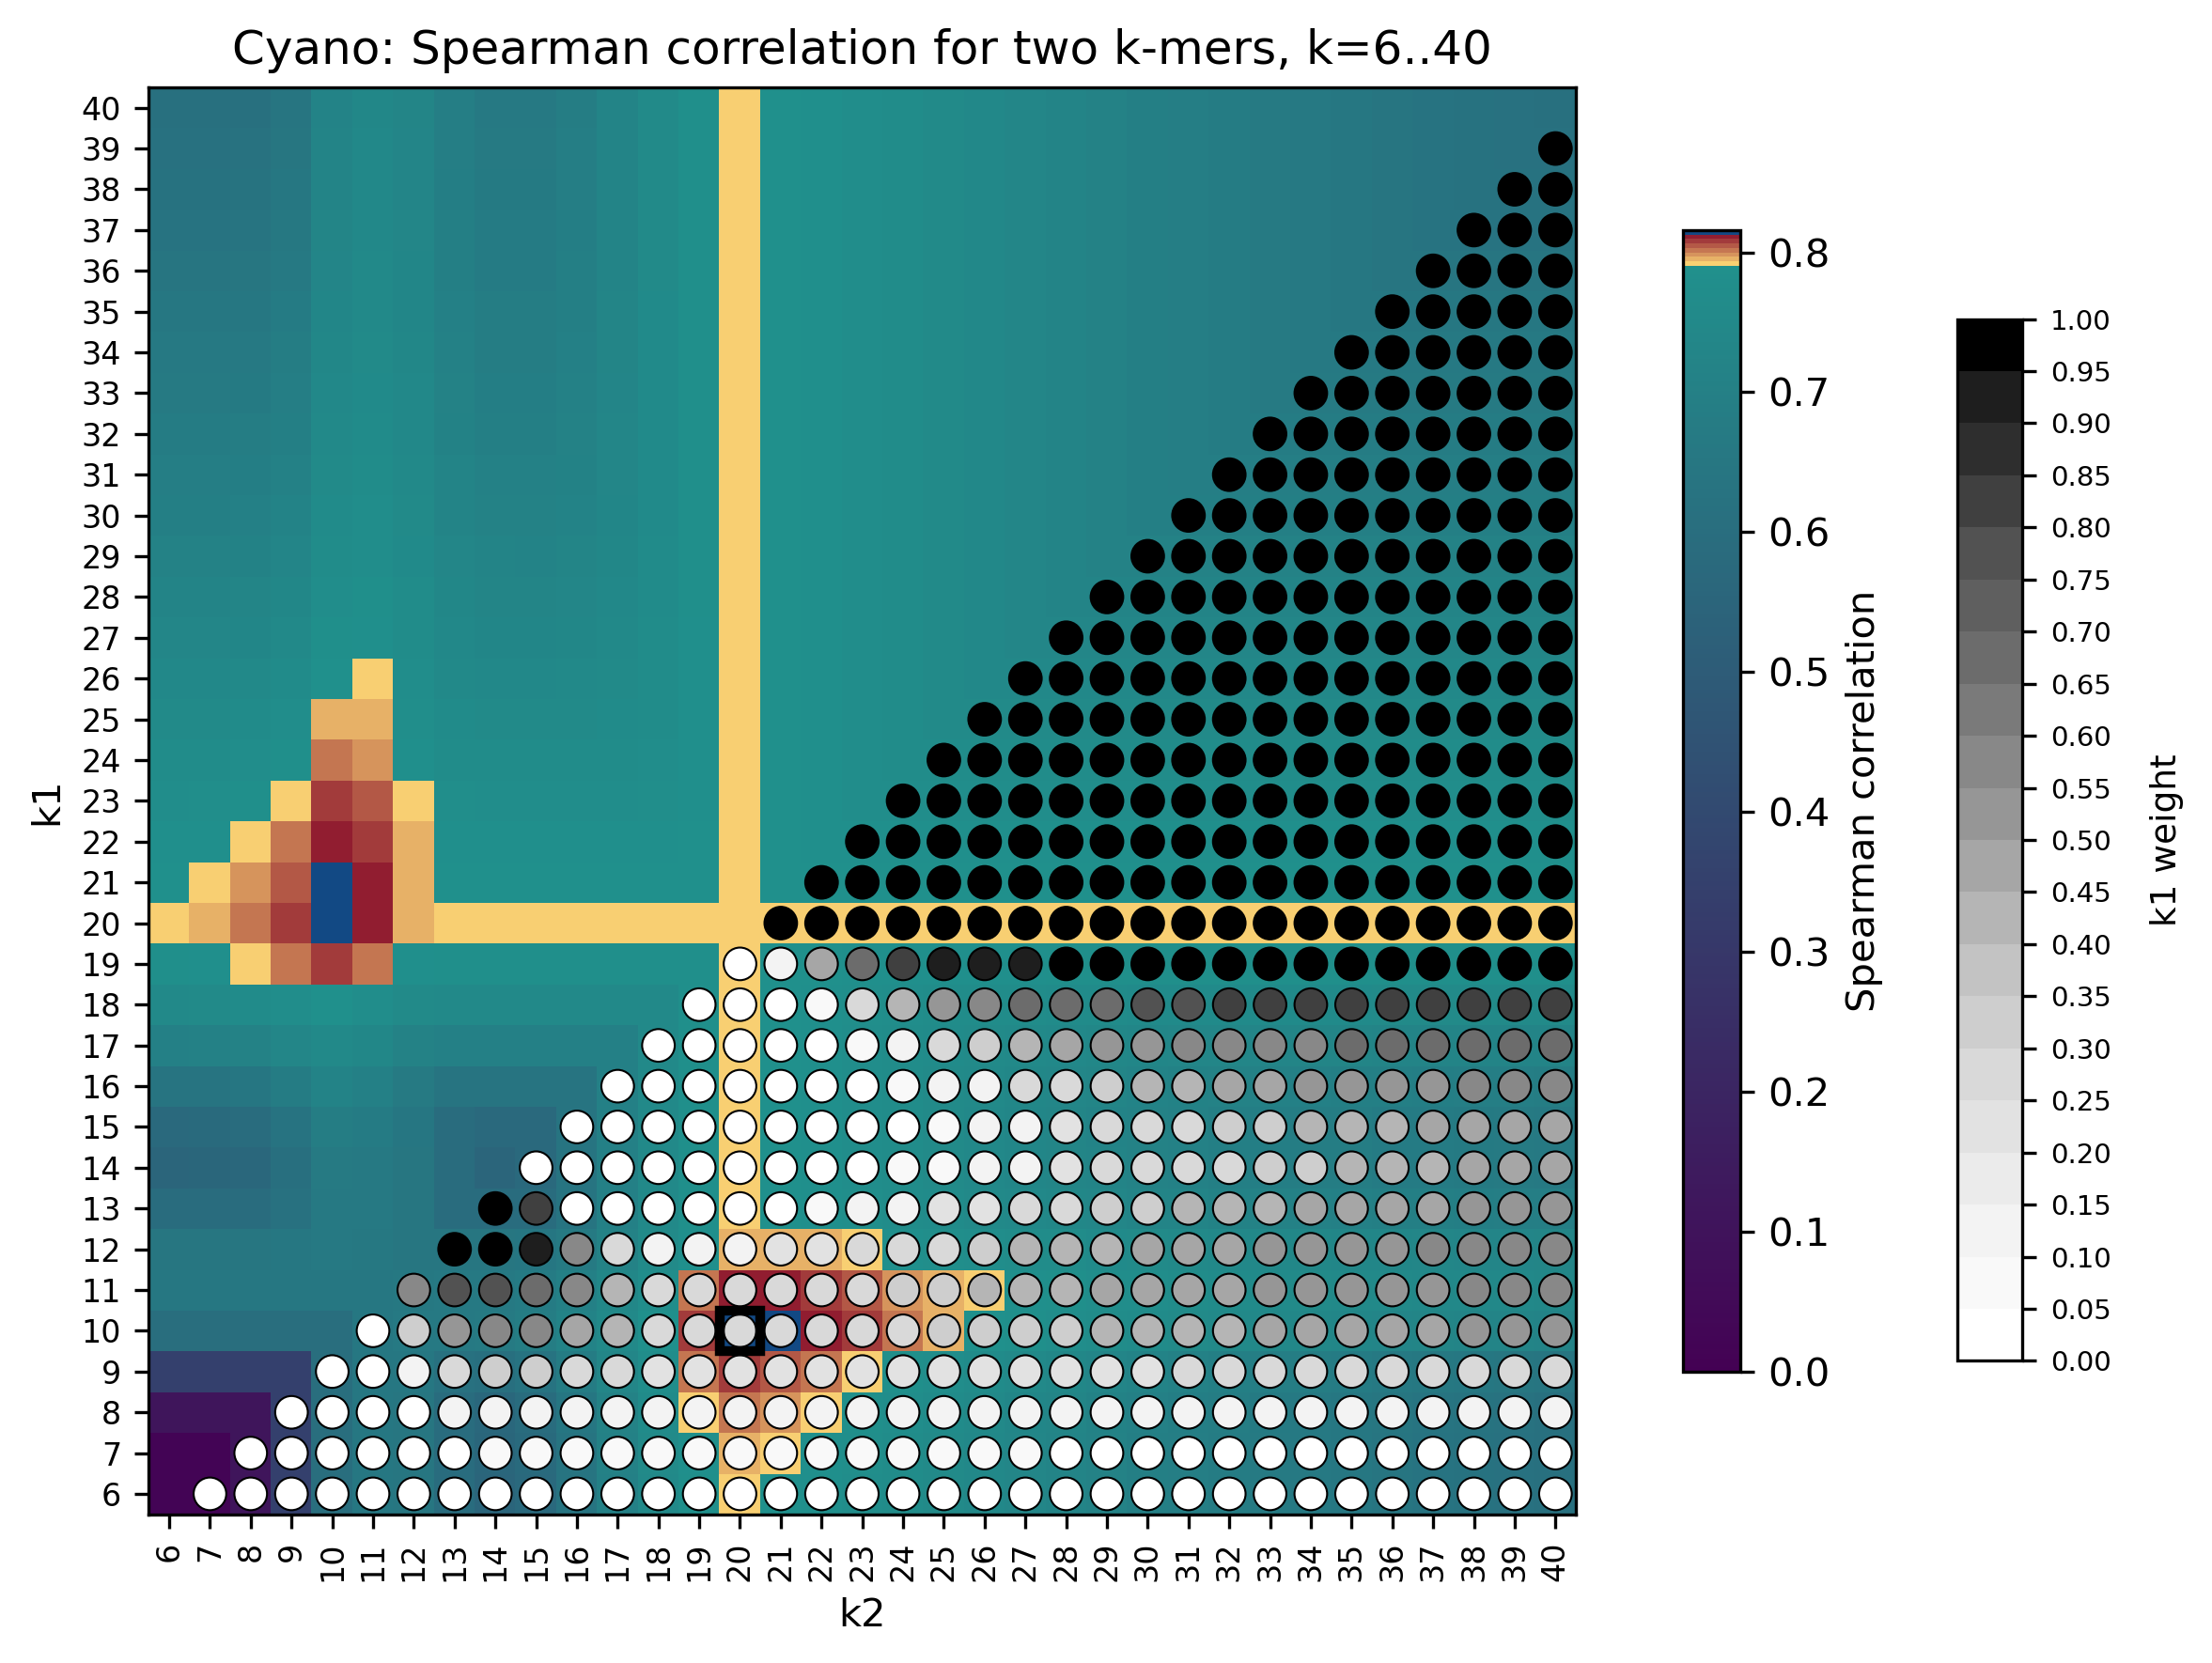


Neisseriaceae
(array([4]), array([13])) 0.9102818641263019


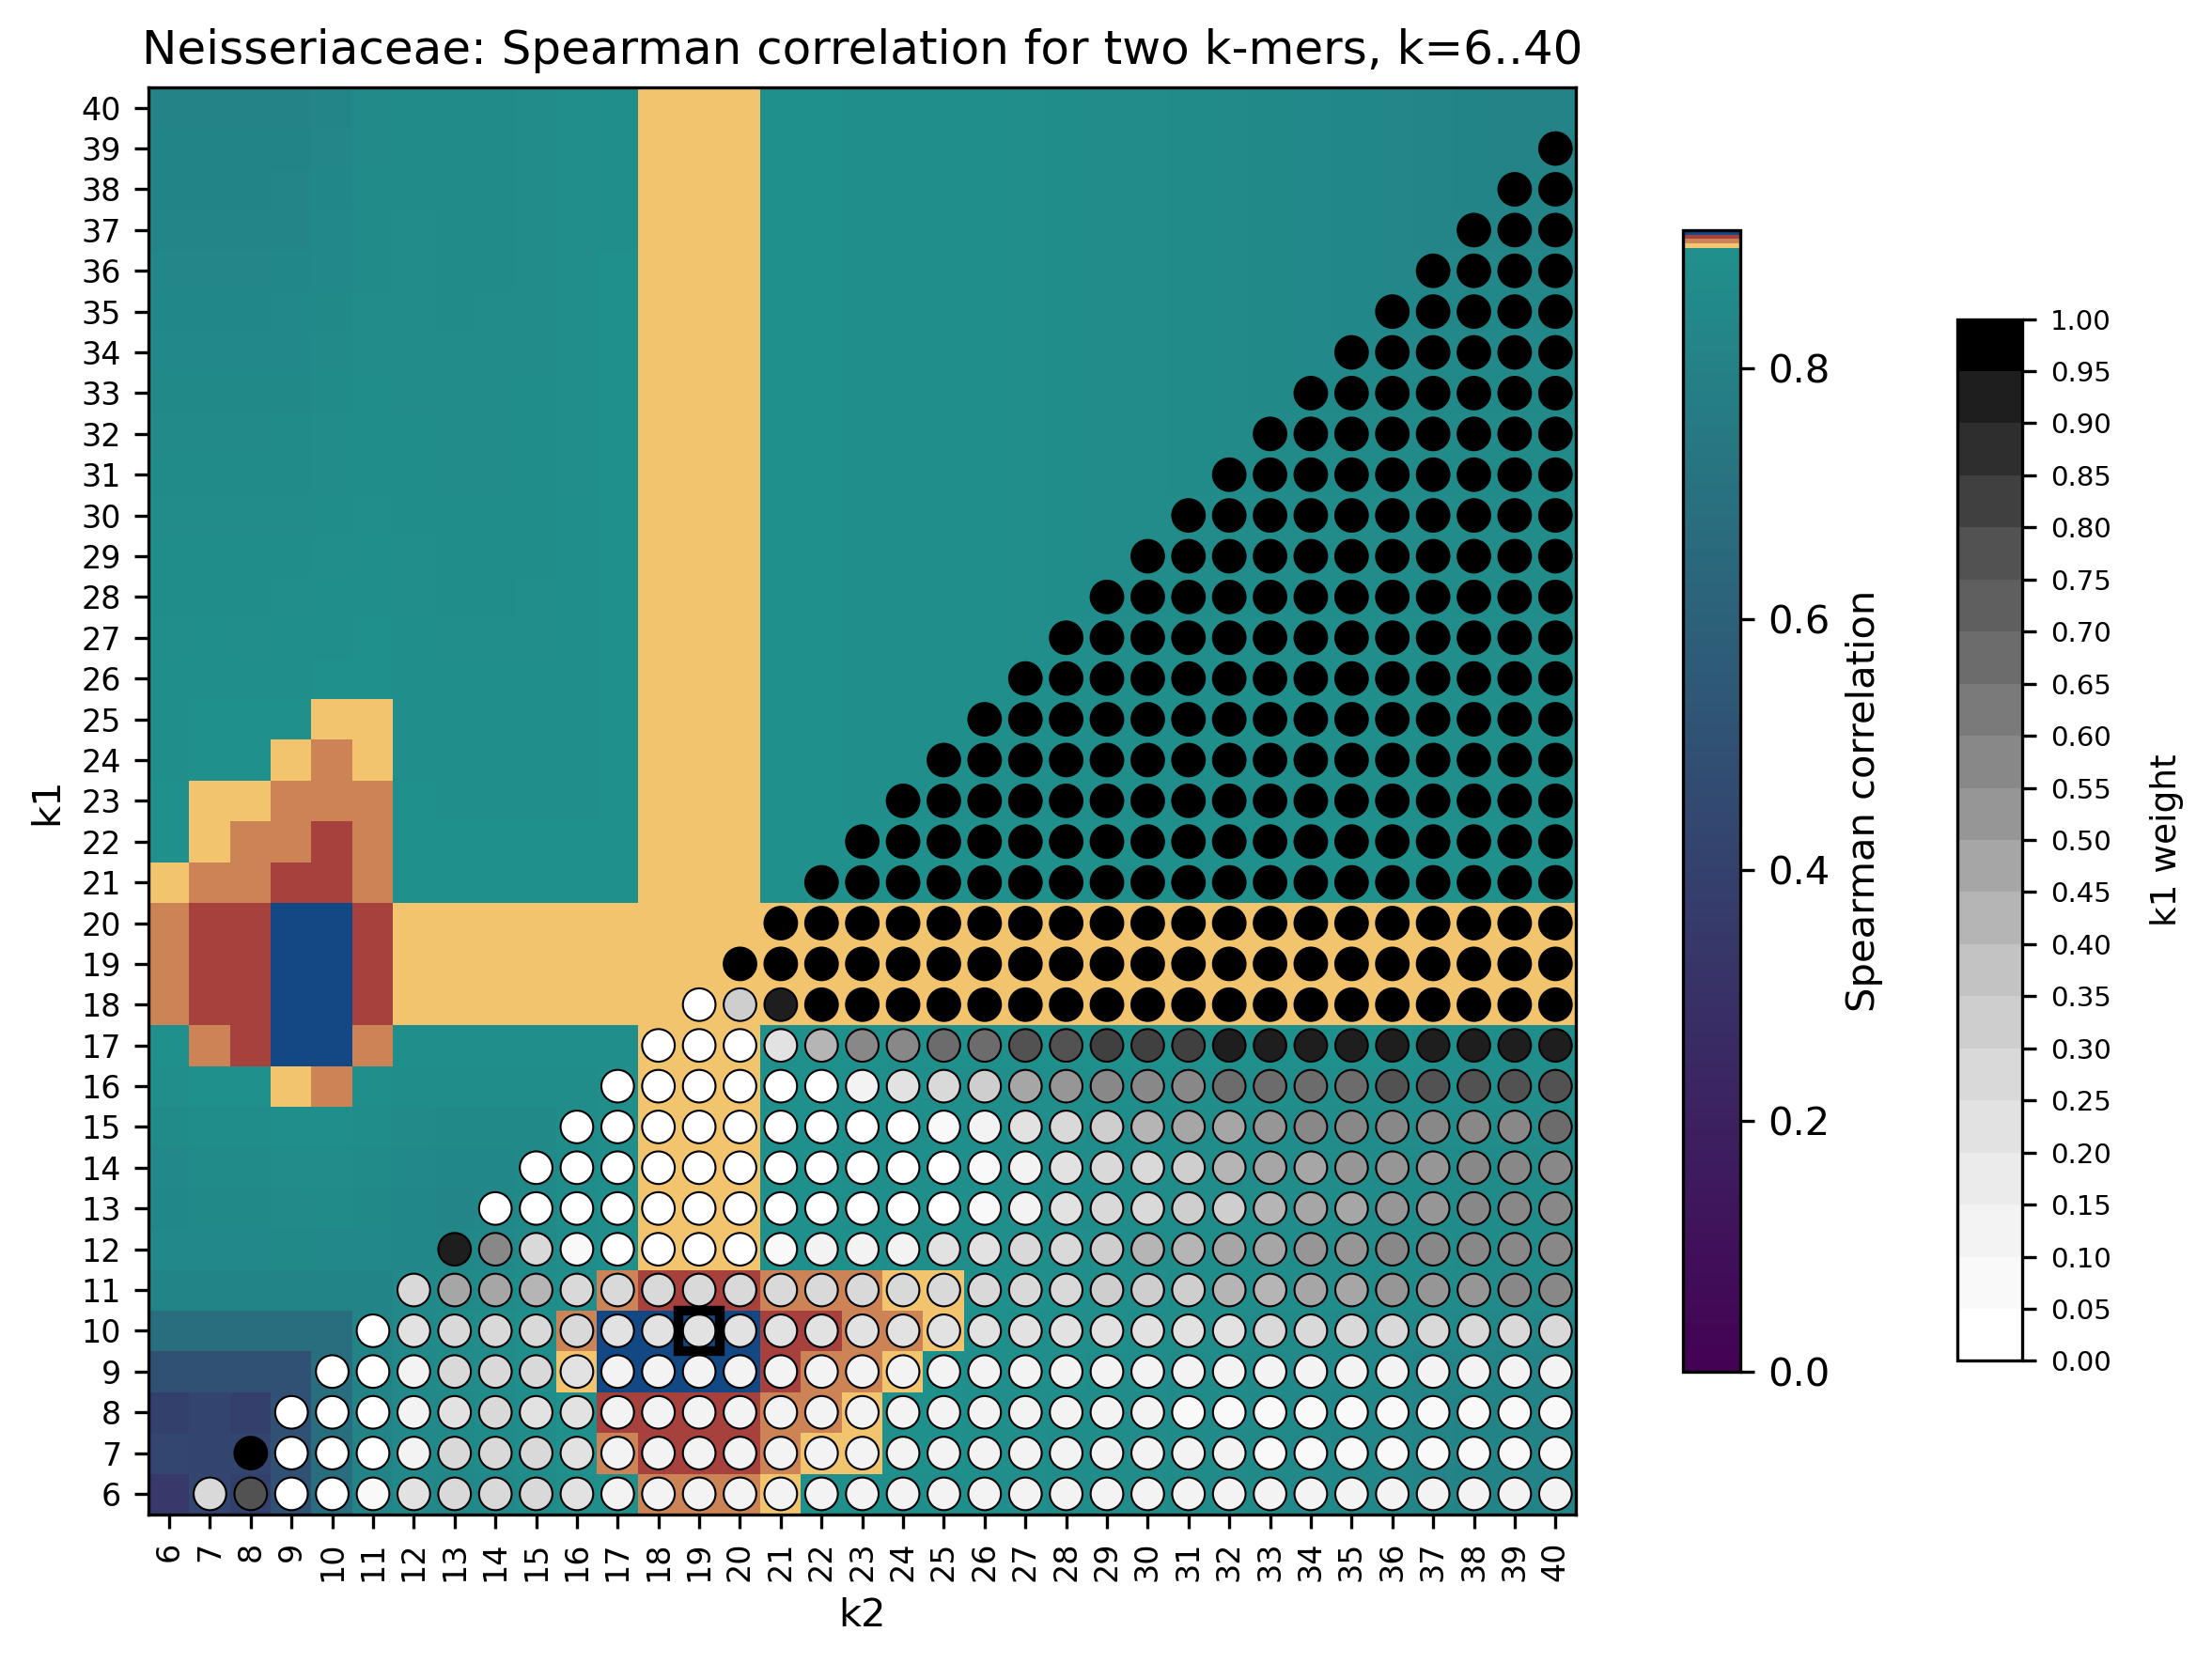

In [15]:
# Run full grid search
for name, results_matrix in datasets_2k:
    print(name)
    results_matrix = np.abs(results_matrix)
    # results_matrix, min_val, k1_min, k2_min, w_min, min_val = ok_k_mer.run_full_grid_corr(merged_df, k_low=6, k_high=40, w_low=0.05)   # run grid search, now is a slurm script
    ok_k_mer.plot_2k_grid_joint_corr_weight(name, results_matrix, k_low=6, k_high=40, cmap_vmax=cmap_dict[name])
    # ok_k_mer.plot_2k_grid_corr(name, results_matrix, k_low=6, k_high=40, cmap_vmax=cmap_dict[name])
    # ok_k_mer.plot_2k_grid_weights(name, results_matrix, k_low=6, k_high=40, w_low=0, w_high=1, w_step=0.05)
    print()


### Three k-mers

In [ ]:
# Run across all datasets

s = 2 # s = 3
k_low = 6
k_high = 40

# Run 3-kmer grid search
for name, grid_df, k_best in datasets_3k:
    print(name, k_best)
    results = ok_k_mer.plot_3k_grid_corr(name, grid_df, k_best, s=s, k_low=k_low, k_high=k_high, cmap_vmax=cmap_dict[name])
    print()


## Plot k-mer cardinality
f(G1, G2, k) = G1(k) U G2(k) / 4**k


In [ ]:
# plot k-mer cardinalities
k_min = 5
k_max = 40

for name, df in cardinality_datasets:
    print(f"Plotting k-mer cardinality for {name}")
    ok_k_mer.plot_kmer_dashing_card(df, name, k_min=k_min, k_max=k_max)
    ok_k_mer.plot_kmer_dashing_card(df, name, k_min=k_min, k_max=k_max, log=True)
    print()

# def plot_kmer_dashing_card(merged_card_df, name, k_min=5, k_max=64, log=False):


## Tree annotated by k-mer recs
